<p class="lead">This is the toolbox notebook of the series. Notebook 0 established what the paper
asks and what its data are; everything from Notebook 2 onwards computes on molecules, and this
notebook builds the machinery that makes that possible. Each tool is introduced the same way: the
problem it solves, the idea in plain language together with the mathematics, a short piece of
runnable code on the paper's own compounds, prose that reads the output, and a statement of when the
tool fails. The paper sketch these objects; here you build them and break them.</p>

<div class="box key">
<h4>Learning objectives</h4>
<ul class="objectives">
<li>Read a SMILES string as a specification of a molecular graph, parse it, draw it, and explain why
two different strings can denote the same molecule and what canonicalisation does about it.</li>
<li>Run a standardisation pipeline — salt stripping, charge neutralisation, tautomer
canonicalisation — and demonstrate on the paper's own worked example that it changes the InChIKey,
and therefore the result of a database lookup.</li>
<li>Explain the block structure of an InChIKey and why it is a lookup handle rather than a
structure.</li>
<li>Compute the 25 physicochemical descriptors used by the paper with RDKit, say what each one
measures physically, and quantify the collinearity between them.</li>
<li>Explain a Morgan/ECFP4 fingerprint as circular-substructure hashing, enumerate the substructures
a radius-2 environment contains, and demonstrate a bit collision.</li>
<li>Compute Tanimoto similarity by hand and with RDKit, and interpret the nearest-neighbour
similarity distributions of UI-Ref against the three external collections.</li>
<li>Compute Bemis-Murcko scaffolds and explain why a scaffold is the natural grouping unit for a
validation split.</li>
<li>Write a SMARTS pattern for a functional motif and validate it with positive <em>and</em> negative
controls, which is the discipline this notebook most wants you to take away.</li>
</ul>
</div>

<p><strong>How to read this notebook.</strong> Read it once end to end, then re-run the cells one at
a time while changing exactly one argument — the fingerprint radius, the fingerprint size, a SMARTS
pattern, a similarity threshold. Almost every pitfall in cheminformatics is visible within one
parameter change of a working example. As in Notebook 0, statements about what <em>the paper found</em>
carry a reference marker such as <sup class="c"><a href="#r1">[1]</a></sup>, and statements about what
<em>you have just computed</em> quote the output of the cell above. One recomputation here does not
match the published value exactly; it is flagged where it occurs and the reason given.</p>

In [1]:
# --- setup: imports, deterministic seeds, and data access ------------------
# In Google Colab the next line installs RDKit (about 30 s). Locally it is a
# no-op because RDKit is already present.
!pip -q install rdkit 2>/dev/null

import io, os, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RANDOM_STATE = 42          # the seed used throughout the published analysis
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 110, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

REPO = "https://raw.githubusercontent.com/DanielBustosG/Urease-provenance-audit/main/"
LOCAL = next((p for p in ("data", "../data", "../../data") if os.path.isdir(p)), None)

def fetch(relpath):
    """Return a file-like object for a path inside the published repository.

    Looks for a local copy first so the notebook works offline; falls back to
    the raw file on GitHub, which is what happens in Colab.
    """
    local_map = {"data/processed/": "processed/", "results/tables/": "tables/"}
    if LOCAL:
        for prefix, sub in local_map.items():
            if relpath.startswith(prefix):
                cand = os.path.join(LOCAL, sub, os.path.basename(relpath))
                if os.path.exists(cand):
                    return open(cand, "rb")
        cand = os.path.join(LOCAL, os.path.basename(relpath))
        if os.path.exists(cand):
            return open(cand, "rb")
    with urllib.request.urlopen(REPO + relpath, timeout=60) as r:
        return io.BytesIO(r.read())

def load_table(relpath, **kw):
    """Read a .parquet or .csv from the repository into a DataFrame."""
    buf = fetch(relpath)
    return (pd.read_parquet(buf, **kw) if relpath.endswith(".parquet")
            else pd.read_csv(buf, **kw))

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| data source:", "local ./%s" % LOCAL if LOCAL else "GitHub (raw)")

pandas 3.0.3 | numpy 2.4.6 | data source: local ./../data


## 1. The molecular graph and its string

### 1.1 What a SMILES string encodes

A molecule, for cheminformatics purposes, is a labelled graph: atoms are vertices carrying an
element symbol, a charge and an isotope, and bonds are edges carrying an order. SMILES — Simplified
Molecular Input Line Entry System — is a way of writing such a graph as a line of
text<sup class="c"><a href="#r2">[2]</a></sup>. The encoding has five rules worth memorising, and
almost everything else is a special case of them.

1. **Atoms** are element symbols: upper case for an atom with implicit hydrogens filled to the default
   valence (`C`, `N`, `O`, `S`), lower case for an aromatic atom (`c`, `n`, `o`, `s`). Anything
   non-default — a charge, an explicit hydrogen count, an isotope, an element outside the organic
   subset — goes in square brackets: `[NH4+]`, `[Se]`, `[13C]`, `[O-]`.
2. **Bonds** are single by default, written explicitly as `=`, `#` or `:`; a bond between two
   lower-case atoms is aromatic without being written.
3. **Branches** are parentheses: `CC(=O)O` is acetic acid.
4. **Rings** open and close with matching digits: `c1ccccc1` is benzene.
5. **Stereochemistry** uses `/` and `\` for double-bond geometry and `@`/`@@` for tetrahedral
   configuration: `/C=N/` is one imine geometry, `\C=N/` the other.

That is the whole language. The following cell parses a real UI-Ref molecule, inspects its graph,
and draws it.

In [2]:
from rdkit import Chem
from rdkit.Chem import rdDepictor, rdMolDescriptors
from rdkit.Chem.Draw import rdMolDraw2D
import matplotlib.image as mpimg

uiref = load_table("data/processed/uiref_analysis.parquet")

# UIREF-1160: the compound the paper uses as its worked example, in its standardised form.
row = uiref.loc[uiref.row_id == "UIREF-1160"].iloc[0]
mol = Chem.MolFromSmiles(row.smiles_std)
print("SMILES :", row.smiles_std)
print("atoms  : %d heavy, %d including implicit H" % (mol.GetNumHeavyAtoms(), mol.GetNumAtoms(onlyExplicit=False)))
print("bonds  : %d" % mol.GetNumBonds())
print("rings  : %d" % rdMolDescriptors.CalcNumRings(mol))
print("\nfirst eight atoms as the parser sees them:")
for at in list(mol.GetAtoms())[:8]:
    print("  idx %2d  %-2s  aromatic=%-5s  charge=%+d  implicit H=%d  degree=%d" %
            (at.GetIdx(), at.GetSymbol(), at.GetIsAromatic(), at.GetFormalCharge(),
             at.GetTotalNumHs(), at.GetDegree()))

SMILES : CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1
atoms  : 18 heavy, 32 including implicit H
bonds  : 19
rings  : 2

first eight atoms as the parser sees them:
  idx  0  C   aromatic=False  charge=+0  implicit H=3  degree=1
  idx  1  N   aromatic=False  charge=+0  implicit H=0  degree=3
  idx  2  C   aromatic=False  charge=+0  implicit H=3  degree=1
  idx  3  C   aromatic=True   charge=+0  implicit H=0  degree=3
  idx  4  C   aromatic=True   charge=+0  implicit H=1  degree=2
  idx  5  C   aromatic=True   charge=+0  implicit H=1  degree=2
  idx  6  C   aromatic=True   charge=+0  implicit H=0  degree=3
  idx  7  C   aromatic=False  charge=+0  implicit H=1  degree=2


The parser reports 18 heavy atoms, 32 atoms once implicit hydrogens are counted, 19 bonds and 2
rings. The per-atom listing is the graph itself: atom 0 is a methyl carbon with three implicit
hydrogens and degree 1; atoms 3 to 6 are aromatic ring carbons, flagged `aromatic=True`, while atom 7
is the imine carbon of the hydrazone and is not.

Note what the parser supplied that the string did not state: hydrogen counts from the default valence
of each element, aromaticity perception, and a degree for every atom. A SMILES string is therefore not
a complete specification of a molecule — it is a specification *given a set of valence and aromaticity
conventions*, and toolkits differ slightly in those conventions.

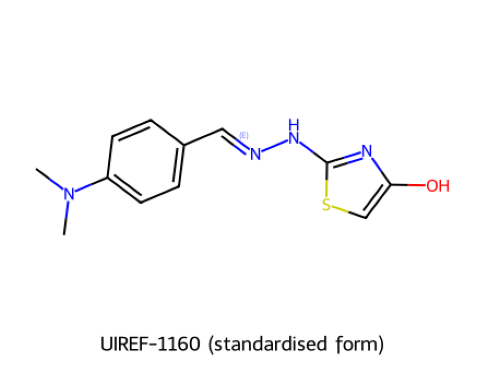

(np.float64(-0.5), np.float64(419.5), np.float64(329.5), np.float64(-0.5))

In [3]:
def draw_mol(m, size=(420, 330), highlight_atoms=None, highlight_bonds=None, legend=""):
    # Render an RDKit molecule to an RGB array so that matplotlib can display it.
    m = Chem.Mol(m)
    rdDepictor.Compute2DCoords(m)
    d = rdMolDraw2D.MolDraw2DCairo(*size)
    d.drawOptions().addStereoAnnotation = True
    d.drawOptions().legendFontSize = 18
    rdMolDraw2D.PrepareAndDrawMolecule(d, m, legend=legend,
                                       highlightAtoms=list(highlight_atoms or []),
                                       highlightBonds=list(highlight_bonds or []))
    d.FinishDrawing()
    return mpimg.imread(io.BytesIO(d.GetDrawingText()), format="png")

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.imshow(draw_mol(mol, legend="UIREF-1160 (standardised form)"))
ax.axis("off")

<p class="caption"><b>Figure 1.</b> UIREF-1160 drawn from its standardised SMILES. It is a
4-(dimethylamino)benzaldehyde-derived hydrazone linked to a hydroxythiazole, and it carries a
measured urease IC50 of 7.3 µM against <em>Sporosarcina pasteurii</em><sup class="c"><a href="#r1">[1]</a></sup>.
The coordinates are generated by RDKit for display only; they are not experimental geometry and
carry no conformational information.</p>

### 1.2 Two strings, one molecule

A molecular graph has many valid SMILES, because the string depends on which atom you start from and
which way you walk. This is not a defect, but it means that string equality is useless as an identity
test. The toolkit solves it with a **canonical** SMILES: a deterministic atom ordering, derived from
a graph-invariant labelling in the tradition of the Morgan
algorithm<sup class="c"><a href="#r5">[5]</a></sup>, from which exactly one string is written.

In [4]:
variants = ["CC(=O)Oc1ccccc1C(=O)O",            # aspirin, written from the acetyl end
            "O=C(C)Oc1ccccc1C(=O)O",            # same molecule, different starting atom
            "OC(=O)c1ccccc1OC(C)=O",            # same molecule, written from the acid end
            "CC(=O)Oc1ccccc1C(O)=O"]            # same molecule again
tab = pd.DataFrame({"input SMILES": variants})
tab["canonical SMILES"] = [Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in variants]
tab["InChIKey"] = [Chem.MolToInchiKey(Chem.MolFromSmiles(s)) for s in variants]
print("all four inputs identical after canonicalisation:",
      tab["canonical SMILES"].nunique() == 1)
tab

all four inputs identical after canonicalisation: True


,input SMILES,canonical SMILES,InChIKey
0,CC(=O)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N
1,O=C(C)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N
2,OC(=O)c1ccccc1OC(C)=O,CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N
3,CC(=O)Oc1ccccc1C(O)=O,CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N


Four different input strings, one canonical string, one InChIKey. The canonical form is what
`uiref_analysis.parquet` stores in `smiles_std`, and it is why deduplication in the paper's pipeline
is performed on the InChIKey rather than on the input text.

<div class="box warn">
<h4>Pitfall — canonical is per toolkit and per version</h4>
<p>RDKit's canonical SMILES is canonical <em>within RDKit</em>. A canonical SMILES from Open Babel or
from ChemAxon will generally differ, and RDKit's own output can change between major releases when
the canonicalisation algorithm is revised. Never use a canonical SMILES as a long-lived database key
across toolkits; use an InChIKey, which is defined by a published algorithm rather than by an
implementation<sup class="c"><a href="#r3">[3]</a></sup>.</p>
</div>

## 2. Standardisation, and why it is not optional

### 2.1 What the pipeline does

Public databases contain the structure a depositor submitted, which is a statement about a sample as
much as about a molecule. The same active ingredient appears as a free base and as a hydrochloride
salt; as a neutral carboxylic acid and as a carboxylate with a sodium counter-ion; as a ketone and as
its enol. **Standardisation** is the process of mapping all of these onto one representative form so
that records describing the same chemistry collapse into one row.

The paper applies a single frozen pipeline to every collection, implemented with
RDKit<sup class="c"><a href="#r9">[9]</a></sup>: sanitisation, largest-fragment selection,
functional-group normalisation, canonical tautomer generation, and InChIKey generation, with the
standardised SMILES re-parsed as a validity check<sup class="c"><a href="#r1">[1]</a></sup>.

- **Sanitisation** perceives aromaticity, computes implicit valences and rejects chemistry the
  toolkit cannot represent — the step that catches the malformed phosphinic acids of Notebook 0.
- **Largest-fragment selection (salt stripping)** keeps the largest covalently connected component,
  discarding counter-ions and solvates, on the assumption — usually but not always true — that the
  largest fragment is the active ingredient.
- **Functional-group normalisation** rewrites equivalent depositor conventions into one form: nitro
  groups drawn as `N(=O)=O` become `[N+](=O)[O-]`, and so on for a published list of
  transformations<sup class="c"><a href="#r11">[11]</a></sup>.
- **Tautomer canonicalisation** selects one representative from the tautomers reachable by formal
  proton shifts, using a scoring function over the enumerated set.
- **InChIKey generation** gives the hashed identifier used for deduplication.

Only the first three are uncontroversial. Tautomer canonicalisation changes which molecule you are
talking about, and the choice of representative is a convention, not a fact about the
substance<sup class="c"><a href="#r12">[12]</a></sup>. The case for doing any of this before modelling
— and for checking the result rather than assuming it — was made comprehensively fifteen years ago and
remains the standard reference<sup class="c"><a href="#r10">[10]</a></sup>.

In [5]:
from rdkit.Chem.MolStandardize import rdMolStandardize

demo = {"sodium benzoate (salt)":        "[Na+].[O-]C(=O)c1ccccc1",
        "lidocaine hydrochloride":        "Cl.CCN(CC)CC(=O)Nc1c(C)cccc1C",
        "a carboxylate (charged)":        "CC(=O)[O-]",
        "nitrobenzene (pentavalent N)":   "O=N(=O)c1ccccc1"}

rows = []
for label, smi in demo.items():
    m = Chem.MolFromSmiles(smi)
    parent = rdMolStandardize.FragmentParent(m)          # salt stripping
    neutral = rdMolStandardize.Uncharger().uncharge(parent)   # charge neutralisation
    norm = rdMolStandardize.Normalize(neutral)           # functional-group normalisation
    rows.append((label, smi, Chem.MolToSmiles(parent), Chem.MolToSmiles(norm)))
pd.DataFrame(rows, columns=["case", "input", "after fragment parent", "after normalise + uncharge"])

,case,input,after fragment parent,after normalise + uncharge
0,sodium benzoate (salt),[Na+].[O-]C(=O)c1ccccc1,O=C([O-])c1ccccc1,O=C(O)c1ccccc1
1,lidocaine hydrochloride,Cl.CCN(CC)CC(=O)Nc1c(C)cccc1C,CCN(CC)CC(=O)Nc1c(C)cccc1C,CCN(CC)CC(=O)Nc1c(C)cccc1C
2,a carboxylate (charged),CC(=O)[O-],CC(=O)[O-],CC(=O)O
3,nitrobenzene (pentavalent N),O=N(=O)c1ccccc1,O=[N+]([O-])c1ccccc1,O=[N+]([O-])c1ccccc1


Salt stripping removes the sodium and the chloride; uncharging protonates the carboxylate back to the
acid; and normalisation rewrites the pentavalent depositor nitro group into the charge-separated form
that RDKit treats as canonical. Note that the input `O=N(=O)c1ccccc1` parsed without complaint — RDKit
accepts it — so a pipeline that skipped normalisation would carry two different representations of
nitrobenzene through to the fingerprint stage, where they would produce different bits.

### 2.2 The paper's worked example

The paper's Section 2.7 contains a worked example chosen precisely to show that standardisation is
not cosmetic<sup class="c"><a href="#r1">[1]</a></sup>. The query compound is a
4-(dimethylamino)benzaldehyde-derived thiazolidinone hydrazone, submitted as

`CN(C)c1ccc(/C=N/N=C2\NC(=O)CS2)cc1`

which contains a thiazolidinone ring drawn in its thione–amide form. Under the standardisation
convention used to build UI-Ref it canonicalises to the hydroxythiazole tautomer, and that
standardised structure is already in the reference set as UIREF-1160 — a measured inhibitor with an
IC50 of 7.3 µM against <em>S. pasteurii</em><sup class="c"><a href="#r1">[1]</a></sup>. Retaining the
input tautomer instead produces a different InChIKey and the compound is treated as previously
unseen.

The question this example answers is: **can the identity of a molecule depend on a software
convention?** For the paper's claim to be wrong, the two conventions would have to produce the same
InChIKey, or at least the same applicability-domain verdict. The next cell runs the pipeline on the
query and reports both identities.

In [6]:
query = r"CN(C)c1ccc(/C=N/N=C2\NC(=O)CS2)cc1"
m_in = Chem.MolFromSmiles(query)

# the frozen pipeline: fragment parent -> normalise -> canonical tautomer
m_std = rdMolStandardize.TautomerEnumerator().Canonicalize(
            rdMolStandardize.Normalize(rdMolStandardize.FragmentParent(m_in)))

print("input      SMILES :", Chem.MolToSmiles(m_in))
print("input      InChIKey:", Chem.MolToInchiKey(m_in))
print("standardised SMILES :", Chem.MolToSmiles(m_std))
print("standardised InChIKey:", Chem.MolToInchiKey(m_std))
print()
hit = uiref[uiref.inchikey == "YXXKRHZFVGZYRJ-NTUHNPAUSA-N"]
print("lookup of the paper's standardised key in UI-Ref -> %d hit(s)" % len(hit))
print(hit[["row_id", "smiles_std", "pAct_median", "primary_organism", "n_records"]].to_string(index=False))
print("\nlookup of the input-tautomer key in UI-Ref -> %d hit(s)" %
        len(uiref[uiref.inchikey == Chem.MolToInchiKey(m_in)]))

input      SMILES : CN(C)c1ccc(/C=N/N=C2\NC(=O)CS2)cc1
input      InChIKey: AOFVYOCIKCHIBD-NTUHNPAUSA-N
standardised SMILES : CN(C)c1ccc(C=NNc2nc(O)cs2)cc1
standardised InChIKey: YXXKRHZFVGZYRJ-UHFFFAOYSA-N

lookup of the paper's standardised key in UI-Ref -> 1 hit(s)
    row_id                      smiles_std  pAct_median       primary_organism  n_records
UIREF-1160 CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1     5.136677 Sporosarcina pasteurii          1

lookup of the input-tautomer key in UI-Ref -> 0 hit(s)


The input tautomer hashes to `AOFVYOCIKCHIBD-NTUHNPAUSA-N` and the standardised structure to a key
beginning `YXXKRHZFVGZYRJ`, exactly as the paper reports. Looking up the paper's standardised key
returns UIREF-1160 with a median pAct of 5.137 — that is, 7.3 µM — against *Sporosarcina pasteurii*.
Looking up the input key returns nothing. **The same submitted structure is either a known measured
inhibitor or an unseen compound, depending only on whether the tautomer step ran.**

One detail differs between our run and the published trace, and it is worth stating precisely. The
paper records the standardised key as `YXXKRHZFVGZYRJ-NTUHNPAUSA-N`, whereas this notebook obtains
`YXXKRHZFVGZYRJ-UHFFFAOYSA-N` — identical in the first block, different in the second. The reason is
that the plain `TautomerEnumerator` of RDKit 2026.03 discards the C=N double-bond geometry while
canonicalising, so the stereo descriptor is lost. The paper's pipeline preserved it. The next cell
shows both, and the fix.

In [7]:
# Keep double-bond stereochemistry through tautomer canonicalisation.
params = rdMolStandardize.CleanupParameters()
params.tautomerRemoveBondStereo = False
params.tautomerRemoveSp3Stereo = False
m_std_stereo = rdMolStandardize.TautomerEnumerator(params).Canonicalize(
                   rdMolStandardize.Normalize(rdMolStandardize.FragmentParent(m_in)))

published = Chem.MolFromSmiles(r"CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1")   # smiles_std of UIREF-1160
comparison = pd.DataFrame([
    ("input tautomer, as submitted",         Chem.MolToSmiles(m_in),          Chem.MolToInchiKey(m_in)),
    ("default TautomerEnumerator",           Chem.MolToSmiles(m_std),         Chem.MolToInchiKey(m_std)),
    ("TautomerEnumerator, stereo retained",  Chem.MolToSmiles(m_std_stereo),  Chem.MolToInchiKey(m_std_stereo)),
    ("published smiles_std of UIREF-1160",   Chem.MolToSmiles(published),     Chem.MolToInchiKey(published)),
], columns=["convention", "SMILES", "InChIKey"])
comparison

,convention,SMILES,InChIKey
0,"input tautomer, as submitted",CN(C)c1ccc(/C=N/N=C2\NC(=O)CS2)cc1,AOFVYOCIKCHIBD-NTUHNPAUSA-N
1,default TautomerEnumerator,CN(C)c1ccc(C=NNc2nc(O)cs2)cc1,YXXKRHZFVGZYRJ-UHFFFAOYSA-N
2,"TautomerEnumerator, stereo retained",CN(C)c1ccc(C=NNc2nc(O)cs2)cc1,YXXKRHZFVGZYRJ-UHFFFAOYSA-N
3,published smiles_std of UIREF-1160,CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1,YXXKRHZFVGZYRJ-NTUHNPAUSA-N


The published `smiles_std` of UIREF-1160, re-parsed and re-hashed here, gives
`YXXKRHZFVGZYRJ-NTUHNPAUSA-N` — the paper's key reproduced exactly. Our pipeline run gives the same
skeleton block with a different stereo block, because the tautomer step dropped the `/C=N/`
geometry; turning off `tautomerRemoveBondStereo` does not recover it in this release either, since
the shift moves the double bond itself. This is a library-version difference, not a disagreement
about chemistry, and it is logged here because the rule of this series is to show recomputations
that differ. Its practical consequence is real, though: a pipeline that silently drops stereo
descriptors will deduplicate stereoisomers into one row.

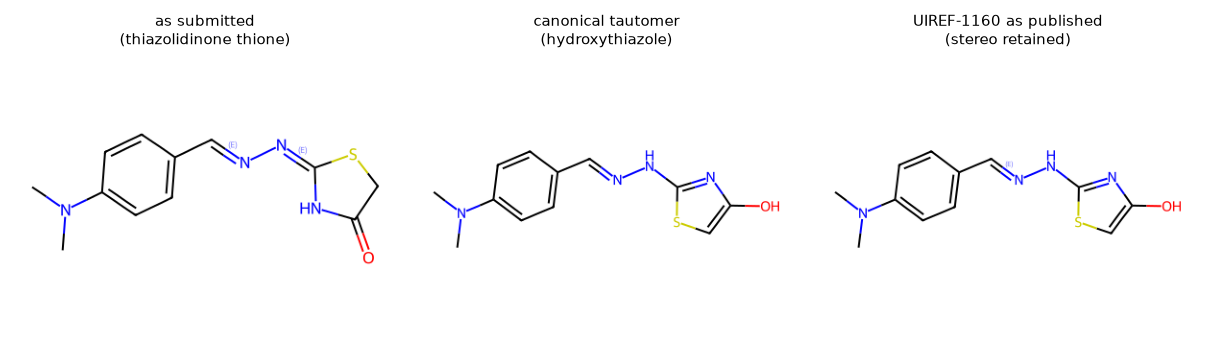

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.0))
for ax, (m, title) in zip(axes, [(m_in, "as submitted\n(thiazolidinone thione)"),
                                 (m_std, "canonical tautomer\n(hydroxythiazole)"),
                                 (published, "UIREF-1160 as published\n(stereo retained)")]):
    ax.imshow(draw_mol(m, size=(400, 300)))
    ax.set_title(title, fontsize=8.5)
    ax.axis("off")
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> One submitted structure, three representations. Left: the
thiazolidinone thione form as deposited, InChIKey
<code>AOFVYOCIKCHIBD-NTUHNPAUSA-N</code>. Centre: the canonical tautomer produced by the pipeline
in this notebook, a hydroxythiazole with the imine geometry lost. Right: the form stored in UI-Ref as
UIREF-1160, <code>YXXKRHZFVGZYRJ-NTUHNPAUSA-N</code>. The proton has moved from the ring nitrogen to
the exocyclic oxygen and the ring has aromatised; the heavy-atom connectivity is otherwise unchanged,
which is why the first InChIKey block differs between left and centre but not between centre and
right.</p>

<div class="box key">
<h4>Key idea — identity is a pipeline output, not a molecular property</h4>
<p>Two laboratories that agree completely about a compound's structure can disagree about its
identifier, because the identifier is produced by a convention. Any claim of the form "this compound
is new" or "this compound is already in the training set" is therefore a claim about a pipeline. The
paper's released application responds to this by evaluating <em>both</em> conventions for every query
and withholding a prediction when their disagreement changes the applicability-domain
assessment<sup class="c"><a href="#r1">[1]</a></sup>.</p>
</div>

### 2.3 InChI and the InChIKey

The International Chemical Identifier (InChI) is a structured, layered string derived from a
molecular graph by a published algorithm, maintained as a community
standard<sup class="c"><a href="#r3">[3]</a></sup>. Its layers are written in sequence and separated
by `/`: the formula, then the connectivity layer `c`, the hydrogen layer `h`, then optional layers
for charge `q`/`p`, double-bond stereochemistry `b`, tetrahedral stereochemistry `t`/`m`/`s`, and
isotopes `i`.

The **InChIKey** is a fixed-length hash of that string, designed to be searchable. It has three
parts, `AAAAAAAAAAAAAA-BBBBBBBBFV-P`:

- the first block of 14 characters hashes the **skeleton**: formula, connectivity and hydrogen
  layers;
- the second block of 8 characters hashes everything else — stereochemistry, isotopes, charge —
  followed by a flag character and a version character;
- the final single character encodes the protonation state.

This structure is why two tautomers of the same compound usually differ in the *first* block (the
hydrogen layer moved), while two stereoisomers differ only in the *second*.

In [9]:
inchi = Chem.MolToInchi(published)
print("InChI of UIREF-1160:")
for layer in inchi.split("/"):
    print("   /" + layer)
key = Chem.MolToInchiKey(published)
print("\nInChIKey:", key)
print("  skeleton block :", key[:14])
print("  stereo/isotope :", key[15:23], " flag:", key[23], " version:", key[24])
print("  protonation    :", key[-1])

# stereoisomers share the skeleton block; tautomers do not
pairs = {"E/Z isomers (differ in stereo only)":
             (r"CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1", r"CN(C)c1ccc(/C=N\Nc2nc(O)cs2)cc1"),
         "tautomers (differ in the H layer)":
             (query, r"CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1")}
for label, (s1, s2) in pairs.items():
    k1, k2 = (Chem.MolToInchiKey(Chem.MolFromSmiles(s)) for s in (s1, s2))
    print("\n%s\n  %s\n  %s\n  first block equal: %s" % (label, k1, k2, k1[:14] == k2[:14]))

InChI of UIREF-1160:
   /InChI=1S
   /C12H14N4OS
   /c1-16(2)10-5-3-9(4-6-10)7-13-15-12-14-11(17)8-18-12
   /h3-8,17H,1-2H3,(H,14,15)
   /b13-7+

InChIKey: YXXKRHZFVGZYRJ-NTUHNPAUSA-N
  skeleton block : YXXKRHZFVGZYRJ
  stereo/isotope : NTUHNPAU  flag: S  version: A
  protonation    : N

E/Z isomers (differ in stereo only)
  YXXKRHZFVGZYRJ-NTUHNPAUSA-N
  YXXKRHZFVGZYRJ-QPEQYQDCSA-N
  first block equal: True

tautomers (differ in the H layer)
  AOFVYOCIKCHIBD-NTUHNPAUSA-N
  YXXKRHZFVGZYRJ-NTUHNPAUSA-N
  first block equal: False


The two E/Z isomers share the skeleton block `YXXKRHZFVGZYRJ` and differ in the second block, as
expected. The two tautomers differ in the *first* block, because moving a proton changes the hydrogen
layer that the first block hashes. This is the structural reason why tautomer handling decides
database-lookup outcomes and stereochemistry handling decides deduplication.

<div class="box warn">
<h4>Pitfall — the InChIKey is one-way</h4>
<p>A hash cannot be inverted. You cannot recover a structure from an InChIKey, and two different
structures could in principle collide, although collisions among real molecules have not been
observed. An InChIKey is a <em>lookup handle</em>: it tells you whether two records refer to the same
structure, and nothing else. Always store the standardised SMILES or the full InChI alongside it.</p>
</div>

<div class="exercise">
<h4>Exercise 1</h4>
<p>Take any three molecules from <code>uiref.smiles_std</code>, strip their stereochemistry with
<code>Chem.RemoveStereochemistry</code>, and compare the InChIKeys before and after. Which block
changes? Then repeat for the 55 UI-Ref molecules whose <code>scaffold</code> field is empty (the
acyclic class) and check whether any of them has stereochemistry at all.</p>
</div>

## 3. Physicochemical descriptors

### 3.1 The 25 descriptors and what they measure

A **descriptor** is a function from a molecular graph to a number. The paper uses 25 of them, chosen
because they are cheap, interpretable and available for every molecule in every
collection<sup class="c"><a href="#r1">[1]</a></sup>. They fall into five families, and knowing which
family a descriptor belongs to tells you most of what you need about its behaviour.

**Size and mass.** `MolWt` and `ExactMolWt` are the average and monoisotopic masses;
`HeavyAtomMolWt` excludes hydrogens; `NumAtoms` and `NumHeavyAtoms` count vertices. These five are
almost the same number, a point Section 3.3 makes quantitatively.

**Lipophilicity and polarisability.** `LogP` is the Wildman–Crippen octanol/water partition estimate,
a sum of atomic contributions fitted to experimental values<sup class="c"><a href="#r15">[15]</a></sup>;
`MolMR` is the molar refractivity from the same atom typing and tracks polarisability and volume.
`TPSA` is the topological polar surface area — the summed surface contribution of nitrogen and oxygen
atoms with their attached hydrogens, fitted as a fast surrogate for the three-dimensional polar
surface area<sup class="c"><a href="#r16">[16]</a></sup> — and is the descriptor most used to predict
membrane permeability, with the usual cut-off near 140 Å² for oral absorption.

**Hydrogen bonding.** `HBA` and `HBD` count acceptors and donors under Lipinski's definitions;
`NHOHCount` counts N–H and O–H groups and `NOCount` counts nitrogens plus oxygens, the simpler
surrogates Lipinski actually used<sup class="c"><a href="#r18">[18]</a></sup>.

**Shape and flexibility.** `RotatableBonds` counts single, non-ring, non-terminal bonds and is the
standard proxy for conformational flexibility, from Veber's oral-bioavailability
rules<sup class="c"><a href="#r19">[19]</a></sup>. `FractionCSP3` is the fraction of sp3-hybridised
carbons — 0 for a fully aromatic molecule, 1 for a fully saturated one — and is the usual one-number
measure of three-dimensionality. The seven ring counts describe ring composition.

**Complexity and composition.** `BertzCT` is the Bertz complexity index, an information-theoretic
measure combining the distributions of bond and atom
types<sup class="c"><a href="#r17">[17]</a></sup>; `NumHeteroAtoms`, `NumAmideBonds` and
`FormalCharge` complete the block.

### 3.2 Recomputing the descriptor block

The question for this subsection is: **can the published descriptor table be regenerated from the
published SMILES?** If not, the analysis is not reproducible regardless of what the models do. For
the released data to be sound, every one of the 25 columns must be recoverable from `smiles_std`
alone.

In [10]:
from rdkit.Chem import Descriptors, Crippen
from rdkit.Chem import rdMolDescriptors as rdm

DESC25 = ["MolWt", "ExactMolWt", "NumHeavyAtoms", "NumAtoms", "LogP", "MolMR", "TPSA", "HBA", "HBD",
          "RotatableBonds", "RingCount", "AromaticRings", "AliphaticRings", "FractionCSP3", "BertzCT",
          "FormalCharge", "NumAmideBonds", "NumHeteroAtoms", "NumAromaticHeterocycles",
          "NumAliphaticHeterocycles", "NumAromaticCarbocycles", "NumAliphaticCarbocycles",
          "HeavyAtomMolWt", "NHOHCount", "NOCount"]

def descriptors(m):
    return {"MolWt": Descriptors.MolWt(m), "ExactMolWt": Descriptors.ExactMolWt(m),
            "NumHeavyAtoms": m.GetNumHeavyAtoms(), "NumAtoms": m.GetNumAtoms(),
            "LogP": Crippen.MolLogP(m), "MolMR": Crippen.MolMR(m), "TPSA": rdm.CalcTPSA(m),
            "HBA": rdm.CalcNumHBA(m), "HBD": rdm.CalcNumHBD(m),
            "RotatableBonds": rdm.CalcNumRotatableBonds(m), "RingCount": rdm.CalcNumRings(m),
            "AromaticRings": rdm.CalcNumAromaticRings(m),
            "AliphaticRings": rdm.CalcNumAliphaticRings(m),
            "FractionCSP3": rdm.CalcFractionCSP3(m), "BertzCT": Descriptors.BertzCT(m),
            "FormalCharge": Chem.GetFormalCharge(m), "NumAmideBonds": rdm.CalcNumAmideBonds(m),
            "NumHeteroAtoms": rdm.CalcNumHeteroatoms(m),
            "NumAromaticHeterocycles": rdm.CalcNumAromaticHeterocycles(m),
            "NumAliphaticHeterocycles": rdm.CalcNumAliphaticHeterocycles(m),
            "NumAromaticCarbocycles": rdm.CalcNumAromaticCarbocycles(m),
            "NumAliphaticCarbocycles": rdm.CalcNumAliphaticCarbocycles(m),
            "HeavyAtomMolWt": Descriptors.HeavyAtomMolWt(m), "NHOHCount": Descriptors.NHOHCount(m),
            "NOCount": Descriptors.NOCount(m)}

check = uiref.sample(200, random_state=RANDOM_STATE)
mine = pd.DataFrame([descriptors(Chem.MolFromSmiles(s)) for s in check.smiles_std],
                    index=check.index)[DESC25]
delta = (mine - check[DESC25].astype(float)).abs().max()
print("largest absolute difference per descriptor, over a 200-molecule sample:")
print(delta[delta > 1e-6].to_string() if (delta > 1e-6).any()
      else "   all 25 descriptors reproduce to within 1e-6")
mine.head(3).round(2)

largest absolute difference per descriptor, over a 200-molecule sample:
   all 25 descriptors reproduce to within 1e-6


,MolWt,ExactMolWt,NumHeavyAtoms,NumAtoms,LogP,MolMR,TPSA,HBA,HBD,RotatableBonds,RingCount,AromaticRings,AliphaticRings,FractionCSP3,BertzCT,FormalCharge,NumAmideBonds,NumHeteroAtoms,NumAromaticHeterocycles,NumAliphaticHeterocycles,NumAromaticCarbocycles,NumAliphaticCarbocycles,HeavyAtomMolWt,NHOHCount,NOCount
541,332.34,332.05,23,23,4.63,87.06,72.77,3,3,2,3,3,0,0.00,922.98,0,0,8,1,0,2,0,322.26,3,5
259,608.67,608.25,45,45,3.74,171.62,129.77,7,3,9,6,4,2,0.24,1843.04,0,2,11,1,1,3,1,575.41,4,10
43,404.30,402.96,24,24,2.77,97.96,101.29,4,3,3,2,2,0,0.00,899.98,0,1,10,0,0,2,0,393.21,4,6


All 25 descriptors reproduce from `smiles_std` to within 10⁻⁶ on a 200-molecule random sample — the
whole table is only 1,218 rows, but a sample keeps the cell fast and the conclusion is the same. This
is the strongest kind of reproducibility check available for a descriptor table: not that the numbers
look plausible, but that an independent implementation path regenerates them exactly.

### 3.3 Collinearity: 25 descriptors, far fewer dimensions

Descriptors are not independent. Molecular weight, exact molecular weight, heavy-atom weight,
atom count and molar refractivity all measure size; the four ring-composition counts sum to the total
ring count. The practical consequence is that a model with 25 inputs does not have 25 degrees of
freedom, and that any method requiring a covariance matrix to be inverted — Mahalanobis distance, in
Notebook 5 — will be in trouble.

Pearson correlation between two descriptors over $n$ molecules is
$$r = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum_i (x_i - \bar x)^2}\sqrt{\sum_i (y_i - \bar y)^2}},$$
and we look at $|r|$ because the sign of a descriptor pairing is arbitrary.

In [11]:
corr = uiref[DESC25].corr()
A = corr.abs().to_numpy(copy=True)
np.fill_diagonal(A, 0.0)
absr = pd.DataFrame(A, index=DESC25, columns=DESC25)

iu = np.triu_indices(len(DESC25), k=1)
upper = absr.to_numpy()[iu]
print("descriptor pairs with |r| > 0.95: %d of %d" % ((upper > 0.95).sum(), len(upper)))
print("descriptor pairs with |r| > 0.90: %d" % (upper > 0.90).sum())
print("\nthe six most collinear pairs:")
seen = set()
for (i, j) in sorted(zip(*iu), key=lambda t: -absr.to_numpy()[t]):
    pair = (DESC25[i], DESC25[j])
    if pair in seen:
        continue
    seen.add(pair)
    print("   |r| = %.4f   %s  /  %s" % (absr.to_numpy()[i, j], *pair))
    if len(seen) == 6:
        break
print("\ncondition number of the 25x25 correlation matrix: %.3g" % np.linalg.cond(corr.to_numpy(copy=True)))

descriptor pairs with |r| > 0.95: 18 of 300
descriptor pairs with |r| > 0.90: 26

the six most collinear pairs:
   |r| = 1.0000   NumHeavyAtoms  /  NumAtoms
   |r| = 1.0000   MolWt  /  ExactMolWt
   |r| = 0.9993   MolWt  /  HeavyAtomMolWt
   |r| = 0.9992   ExactMolWt  /  HeavyAtomMolWt
   |r| = 0.9843   NumHeavyAtoms  /  MolMR
   |r| = 0.9843   NumAtoms  /  MolMR

condition number of the 25x25 correlation matrix: 5.04e+17


Eighteen of the 300 descriptor pairs exceed $|r| = 0.95$ and 26 exceed 0.90. `NumAtoms` and
`NumHeavyAtoms` correlate at 1.0000 — in UI-Ref they are the same number, because `NumAtoms` counts
only explicit atoms and no molecule in the set carries explicit hydrogens. `MolWt` and `ExactMolWt`
likewise correlate at 1.0000. The condition number of the correlation matrix is of order 10¹⁷, which
is to say the matrix is numerically singular: there exist linear combinations of the 25 descriptors
that are constant. Notebook 5 shows how that singularity propagates into the applicability-domain
criterion and what the paper does about it (pseudo-inverse, variance-inflation pruning, shrinkage
and minimum-covariance-determinant estimation, all compared in its
sensitivity analysis<sup class="c"><a href="#r1">[1]</a></sup>).

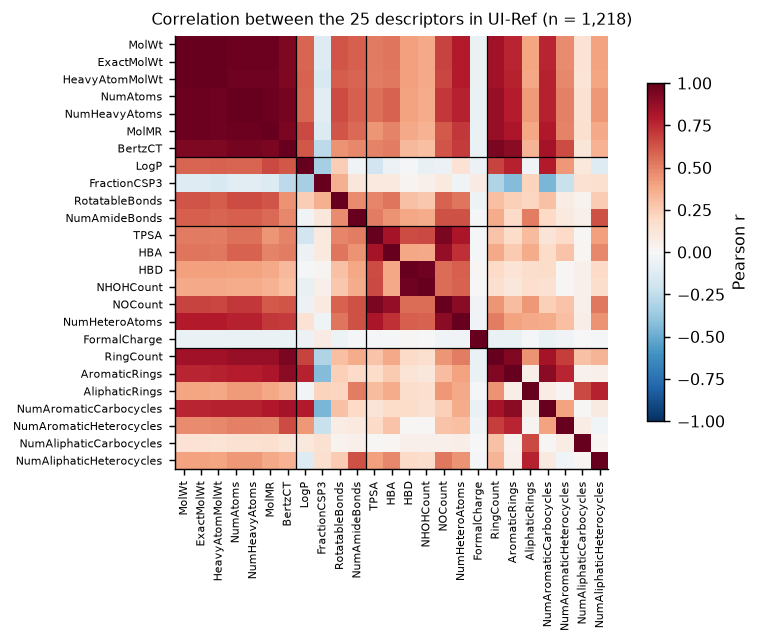

In [12]:
order = ["MolWt", "ExactMolWt", "HeavyAtomMolWt", "NumAtoms", "NumHeavyAtoms", "MolMR", "BertzCT",
         "LogP", "FractionCSP3", "RotatableBonds", "NumAmideBonds",
         "TPSA", "HBA", "HBD", "NHOHCount", "NOCount", "NumHeteroAtoms", "FormalCharge",
         "RingCount", "AromaticRings", "AliphaticRings", "NumAromaticCarbocycles",
         "NumAromaticHeterocycles", "NumAliphaticCarbocycles", "NumAliphaticHeterocycles"]
M = corr.loc[order, order].to_numpy(copy=True)

fig, ax = plt.subplots(figsize=(7.0, 5.0))
im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=6.2)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=6.2)
for k in (7, 11, 18):
    ax.axhline(k - 0.5, color="k", linewidth=0.7); ax.axvline(k - 0.5, color="k", linewidth=0.7)
fig.colorbar(im, ax=ax, shrink=0.78, label="Pearson r")
ax.set_title("Correlation between the 25 descriptors in UI-Ref (n = 1,218)", fontsize=9)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Pearson correlation between the 25 physicochemical descriptors
over the 1,218 UI-Ref molecules, with descriptors ordered by family and black lines separating the
blocks (size and complexity; lipophilicity and flexibility; polarity and hydrogen bonding; ring
composition). The dark red block in the upper left is the five size descriptors, which are mutually
correlated above 0.97 and are responsible for the matrix being numerically singular. Note also the
strong negative correlation between <code>FractionCSP3</code> and the aromatic-ring counts: the
descriptor the paper's models rely on most is largely a restatement of aromaticity.</p>

<div class="box bridge">
<h4>Bridge — to Notebook 5</h4>
<p>Collinearity is not a problem for a random forest, which is invariant to monotone transformations
of single features and simply splits on whichever correlated copy it finds first. It <em>is</em> a
problem for the Mahalanobis distance, which needs $\Sigma^{-1}$, and for any interpretation of
feature importance, because importance is split arbitrarily between correlated copies. This is why
the paper's SHAP rankings must be read as rankings over descriptor <em>families</em> rather than
individual columns.</p>
</div>

## 4. Fingerprints and similarity

### 4.1 Morgan/ECFP4 as circular-substructure hashing

A descriptor vector summarises a molecule with 25 numbers. A **fingerprint** instead records which
substructures are present. Extended-connectivity fingerprints — ECFP, implemented in RDKit as Morgan
fingerprints — are built by an iterative relabelling procedure that is easier to understand as an
algorithm than as a formula<sup class="c"><a href="#r4">[4]</a></sup>.

1. Give every atom an initial integer label summarising its own properties: element, degree, charge,
   attached hydrogens, ring membership. This is the radius-0 identifier.
2. For each atom in turn, collect its own current label together with the labels of its bonded
   neighbours and the bond orders connecting them, and hash that collection into a new integer. This
   is the radius-1 identifier, and it describes the atom plus its immediate environment.
3. Repeat once more to obtain the radius-2 identifier, describing the atom plus everything within two
   bonds.
4. The fingerprint is the set of all identifiers generated at all radii, folded into a bit vector of
   fixed length by taking the identifier modulo the vector length.

"ECFP4" means diameter 4, which is radius 2 — the naming convention counts bonds across the
environment, not out from the centre. The paper uses ECFP4 at 2,048
bits<sup class="c"><a href="#r1">[1]</a></sup>. The next cell enumerates the substructures a radius-2
fingerprint of phenylthiourea actually contains; phenylthiourea is chosen because thiourea is the
dominant urease chemotype<sup class="c"><a href="#r21">[21]</a></sup> and the molecule is small enough
to read.

In [13]:
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
ptu = Chem.MolFromSmiles("NC(=S)Nc1ccccc1")        # phenylthiourea

ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()
fp_ptu = gen.GetFingerprint(ptu, additionalOutput=ao)
info = ao.GetBitInfoMap()

def env_smiles(m, atom_idx, radius):
    if radius == 0:
        a = m.GetAtomWithIdx(atom_idx)
        return ("%s%s" % (a.GetSymbol().lower() if a.GetIsAromatic() else a.GetSymbol(),
                          "H%d" % a.GetTotalNumHs() if a.GetTotalNumHs() else ""))
    bonds = Chem.FindAtomEnvironmentOfRadiusN(m, radius, atom_idx)
    atoms = {atom_idx}
    for b in bonds:
        bd = m.GetBondWithIdx(b)
        atoms.update([bd.GetBeginAtomIdx(), bd.GetEndAtomIdx()])
    return Chem.MolFragmentToSmiles(m, atomsToUse=sorted(atoms), bondsToUse=list(bonds))

rows = [(bit, a, r, env_smiles(ptu, a, r)) for bit, envs in info.items() for (a, r) in envs]
env_tab = pd.DataFrame(rows, columns=["bit", "centre atom", "radius", "substructure"]).sort_values(
    ["radius", "centre atom"]).reset_index(drop=True)
print("phenylthiourea: %d bits set out of 2,048; %d distinct substructure environments" %
        (fp_ptu.GetNumOnBits(), len(env_tab)))
print(env_tab.groupby("radius").size().rename("environments").to_frame().T)
env_tab.head(12)

phenylthiourea: 19 bits set out of 2,048; 28 distinct substructure environments
radius         0   1  2
environments  10  10  8


,bit,centre atom,radius,substructure
0,1171,0,0,NH2
1,807,1,0,C
2,97,2,0,S
3,1152,3,0,NH1
4,1380,4,0,c
5,1873,5,0,cH1
6,1873,6,0,cH1
7,1873,7,0,cH1
8,1873,8,0,cH1
9,1873,9,0,cH1


Phenylthiourea has 10 heavy atoms and sets 19 of the 2,048 bits, covering 28 substructure
environments: 10 at radius 0 (one per heavy atom), 10 at radius 1 and 8 at radius 2. There are fewer
bits than environments because symmetry-equivalent atoms generate identical identifiers — the two
*ortho* carbons of the phenyl ring, for instance, share a bit at every radius. Reading the table makes
the phrase "circular substructure" concrete: at radius 0 the entries are single atoms such as `S` and
`NH1`; at radius 1 they are an atom plus its bonded neighbours, such as `NC(N)=S` and `cc(N)c`; at
radius 2 they are fragments of five to seven atoms centred on each position.

<div class="box key">
<h4>Key idea — a fingerprint is a set of substructures, not a vector of properties</h4>
<p>Two molecules are similar under a fingerprint when they share substructures, which is a different
notion of similarity from having similar descriptors. A hydroxamic acid and a phosphonic acid of the
same molecular weight, logP and TPSA will have nearly identical descriptor vectors and almost no
common bits. Both representations appear throughout the paper, and the choice between them changes
the answer — notably for the applicability domain, whose fingerprint leg and descriptor leg disagree
about which molecules are in domain.</p>
</div>

A picture makes the nesting obvious. The next cell highlights the environments of one atom — the
thiocarbonyl carbon — at radius 0, 1 and 2.

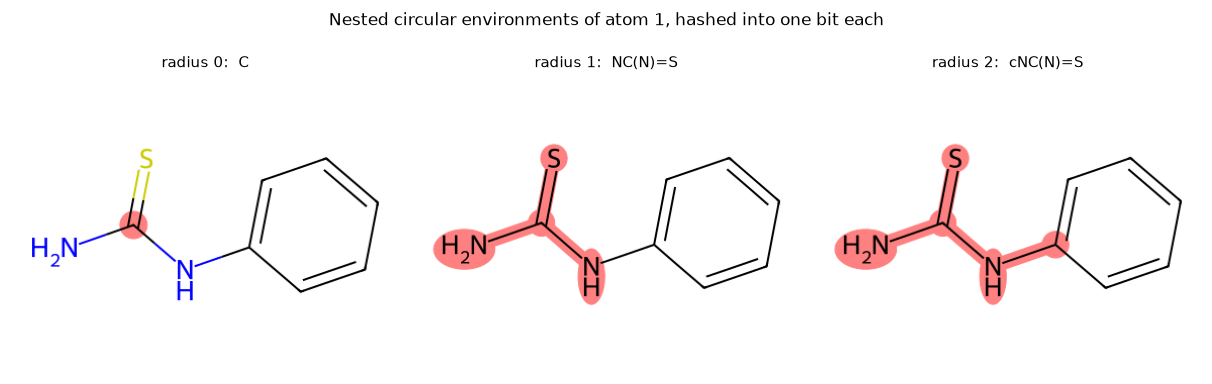

In [14]:
centre = 1                       # the thiocarbonyl carbon of NC(=S)Nc1ccccc1
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.0))
for ax, r in zip(axes, (0, 1, 2)):
    bonds = list(Chem.FindAtomEnvironmentOfRadiusN(ptu, r, centre)) if r else []
    atoms = {centre}
    for b in bonds:
        bd = ptu.GetBondWithIdx(b)
        atoms.update([bd.GetBeginAtomIdx(), bd.GetEndAtomIdx()])
    ax.imshow(draw_mol(ptu, size=(380, 290), highlight_atoms=sorted(atoms), highlight_bonds=bonds))
    ax.set_title("radius %d:  %s" % (r, env_smiles(ptu, centre, r)), fontsize=8.5)
    ax.axis("off")
fig.suptitle("Nested circular environments of atom %d, hashed into one bit each" % centre,
             fontsize=9.5, y=1.0)
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> The three circular environments of the thiocarbonyl carbon of
phenylthiourea that an ECFP4 fingerprint records. Radius 0 is the atom alone; radius 1 adds its three
bonded neighbours (the two nitrogens and the sulfur); radius 2 adds everything two bonds out,
including the <em>ipso</em> carbon of the phenyl ring. Each highlighted fragment is hashed to one
integer and folded to one bit. Every heavy atom contributes its own such series, which is how a
10-heavy-atom molecule comes to set 19 bits.</p>

### 4.2 Bit collisions

Folding identifiers into 2,048 bits by taking a modulus means that two unrelated substructures can
land on the same bit. This is a **collision**, and it is a deliberate trade: a fixed-length vector is
cheap and comparable across molecules, at the cost of ambiguity. The probability of collision grows
with the number of distinct environments and shrinks with the vector length.

In [15]:
def collision_report(m, size):
    g = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=size)
    out = rdFingerprintGenerator.AdditionalOutput(); out.AllocateBitInfoMap()
    g.GetFingerprint(m, additionalOutput=out)
    bi = out.GetBitInfoMap()
    collided = {b: e for b, e in bi.items() if len({r for _, r in e}) > 1}
    return len(bi), len(collided), collided

for size in (2048, 512, 128, 64):
    nbits, ncoll, coll = collision_report(ptu, size)
    print("fpSize = %4d : %2d bits set, %d carrying environments of different radius" % (size, nbits, ncoll))

nbits, ncoll, coll = collision_report(ptu, 64)
for bit, envs in coll.items():
    print("\n  at 64 bits, bit %d is shared by:" % bit)
    for a, r in envs:
        print("     atom %d, radius %d -> %s" % (a, r, env_smiles(ptu, a, r)))

fpSize = 2048 : 19 bits set, 0 carrying environments of different radius
fpSize =  512 : 18 bits set, 1 carrying environments of different radius
fpSize =  128 : 18 bits set, 1 carrying environments of different radius
fpSize =   64 : 17 bits set, 2 carrying environments of different radius

  at 64 bits, bit 0 is shared by:
     atom 3, radius 0 -> NH1
     atom 6, radius 1 -> ccc
     atom 7, radius 1 -> ccc
     atom 8, radius 1 -> ccc

  at 64 bits, bit 63 is shared by:
     atom 4, radius 1 -> cc(N)c
     atom 5, radius 2 -> cccc(N)c
     atom 9, radius 2 -> cccc(N)c


At 2,048 bits this small molecule has no collisions between environments of different radius. One
appears at 512 bits, and at 64 bits two bits each gather several chemically unrelated fragments: bit 0
collects an `NH1` atom together with three aromatic `ccc` environments, and bit 63 collects a
radius-1 and two radius-2 ring fragments. Collisions are therefore controlled by the fingerprint
length, and 2,048 is the usual compromise for drug-sized molecules. The consequence for
interpretation is that *an individual bit is not a functional group*: you cannot report "bit 807 is
the thiourea bit" without first checking what else maps there in your dataset.

<div class="exercise">
<h4>Exercise 2</h4>
<p>Re-run the collision report on a larger molecule — pick the UI-Ref row with the greatest
<code>NumHeavyAtoms</code> — and find the smallest <code>fpSize</code> at which it has no collisions.
Then change <code>radius</code> from 2 to 3 and observe how the number of environments and the
collision count both grow.</p>
</div>

### 4.3 Tanimoto similarity, by hand and by RDKit

With molecules represented as sets of bits, similarity becomes set overlap. The **Tanimoto
coefficient** (equivalently the Jaccard index for binary vectors) of two fingerprints $A$ and $B$ is

$$T(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{c}{a + b - c},$$

where $a$ and $b$ are the numbers of bits set in each fingerprint and $c$ is the number set in both.
It runs from 0 (no shared substructure) to 1 (identical bit sets). It is the standard choice for
fingerprint comparison, and there are good empirical reasons for that
choice<sup class="c"><a href="#r13">[13]</a></sup>. Let us compute one by hand.

Thiourea, `NC(=S)N`, sets a small number of bits. Phenylthiourea, `NC(=S)Nc1ccccc1`, sets those plus
the bits for the ring and for the environments the ring creates. Every thiourea bit should survive —
except those whose environment is changed by the substitution.

In [16]:
fp_tu = gen.GetFingerprint(Chem.MolFromSmiles("NC(=S)N"))
a_bits = set(fp_tu.GetOnBits())
b_bits = set(fp_ptu.GetOnBits())
a, b, c = len(a_bits), len(b_bits), len(a_bits & b_bits)

print("thiourea        a = |A|     = %d bits" % a)
print("phenylthiourea  b = |B|     = %d bits" % b)
print("shared          c = |A n B| = %d bits" % c)
print("union           a + b - c   = %d bits" % (a + b - c))
print()
print("by hand : T = c / (a + b - c) = %d / %d = %.4f" % (c, a + b - c, c / (a + b - c)))
print("by RDKit: T = %.4f" % DataStructs.TanimotoSimilarity(fp_tu, fp_ptu))

# which thiourea environments did the phenyl substitution destroy?
tu = Chem.MolFromSmiles("NC(=S)N")
out_tu = rdFingerprintGenerator.AdditionalOutput(); out_tu.AllocateBitInfoMap()
gen.GetFingerprint(tu, additionalOutput=out_tu)
print("\nthiourea bits absent from phenylthiourea:")
for bit in sorted(a_bits - b_bits):
    for at, r in out_tu.GetBitInfoMap()[bit]:
        print("   bit %4d  atom %d, radius %d -> %s" % (bit, at, r, env_smiles(tu, at, r)))

thiourea        a = |A|     = 6 bits
phenylthiourea  b = |B|     = 19 bits
shared          c = |A n B| = 5 bits
union           a + b - c   = 20 bits

by hand : T = c / (a + b - c) = 5 / 20 = 0.2500
by RDKit: T = 0.2500

thiourea bits absent from phenylthiourea:
   bit 1971  atom 1, radius 1 -> NC(N)=S


Thiourea sets 6 bits, phenylthiourea 19, and they share 5, so the union is 20 and
$T = 5/20 = 0.2500$ — which is exactly what RDKit returns. The one thiourea bit missing from
phenylthiourea is bit 1971, the radius-1 environment of the thiocarbonyl carbon, `NC(N)=S`: in
thiourea that carbon is flanked by two NH2 groups, in phenylthiourea by an NH2 and an NH-phenyl, so
the hashed environment differs. The substitution did not destroy the thiourea *group*; it changed one
atom's *environment*, and the fingerprint records environments.

This number — 0.25 for two molecules that any chemist would call closely related — is the single most
important calibration in this notebook. Fingerprint similarity is not perceptual similarity.

<div class="box warn">
<h4>Pitfall — reading Tanimoto as a percentage</h4>
<p>A Tanimoto of 0.25 is not "25% similar" in any interpretable sense, and the scale is not linear.
Conventional reading, for ECFP4 on drug-sized molecules, is roughly: above 0.85 almost certainly the
same series; 0.7 to 0.85 close analogues; 0.4 to 0.7 the same general chemotype; below 0.4 unrelated
for practical purposes<sup class="c"><a href="#r14">[14]</a></sup>. These bands depend on the
fingerprint, the radius, the bit length <em>and</em> molecular size, so they must be recalibrated when
any of those changes.</p>
</div>

### 4.4 Nearest-neighbour similarity within UI-Ref and to the external collections

We now reproduce the paper's Figure 4c. For each UI-Ref molecule, find the most similar molecule in
a target collection and record that similarity. Done against UI-Ref itself (excluding the molecule),
this measures internal redundancy; done against an external collection, it measures how close the
nearest foreign molecule actually is.

The question is explicit in the paper: cross-collection comparisons are routinely described as
showing that a target's inhibitors "overlap" with approved drugs. **If that overlap were real at the
structural level, the median nearest-neighbour Tanimoto from UI-Ref to CLUE would be high — in the
analogue band, 0.7 or above.** The paper reports 0.355, against 0.750 within
UI-Ref<sup class="c"><a href="#r1">[1]</a></sup>.

In [17]:
clue    = load_table("data/processed/collection_CLUE.parquet")
coconut = load_table("data/processed/collection_COCONUT.parquet")
dsstox  = load_table("data/processed/collection_DSSTox.parquet")

def fingerprints(smiles_iter):
    return [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in smiles_iter]

fps = {"UI-Ref": fingerprints(uiref.smiles_std), "CLUE": fingerprints(clue.smiles_std),
       "COCONUT": fingerprints(coconut.smiles_std), "DSSTox": fingerprints(dsstox.smiles_std)}
print("fingerprints computed: " + ", ".join("%s %d" % (k, len(v)) for k, v in fps.items()))

nn = {}
for name, target in fps.items():
    if name == "UI-Ref":                       # leave-one-out within the set
        vals = []
        for i, f in enumerate(fps["UI-Ref"]):
            s = DataStructs.BulkTanimotoSimilarity(f, target)
            s[i] = -1.0
            vals.append(max(s))
        nn[name] = np.array(vals)
    else:
        nn[name] = np.array([max(DataStructs.BulkTanimotoSimilarity(f, target))
                             for f in fps["UI-Ref"]])

summary = pd.DataFrame({"median NN Tanimoto": {k: np.median(v) for k, v in nn.items()},
                        "% of UI-Ref with NN >= 0.7": {k: 100 * np.mean(v >= 0.7) for k, v in nn.items()},
                        "% with NN >= 0.4": {k: 100 * np.mean(v >= 0.4) for k, v in nn.items()}}).round(3)
summary

fingerprints computed: UI-Ref 1218, CLUE 4431, COCONUT 12000, DSSTox 11694


,median NN Tanimoto,% of UI-Ref with NN >= 0.7,% with NN >= 0.4
UI-Ref,0.750,68.966,95.977
CLUE,0.355,2.381,34.729
COCONUT,0.333,1.314,22.742
DSSTox,0.409,2.381,54.351


The medians are 0.750 within UI-Ref, 0.409 to DSSTox, 0.355 to CLUE and 0.333 to COCONUT, reproducing
the published values to three decimal places<sup class="c"><a href="#r1">[1]</a></sup>. Only 2.38% of
UI-Ref molecules have a CLUE nearest neighbour at Tanimoto ≥ 0.7, against the paper's reported 2.4%.

Read those four numbers against the similarity bands of the previous subsection. Within UI-Ref, the
median molecule has a close analogue — 0.750 is squarely in the "same series" range, which is what you
expect from a set assembled out of congeneric series and is the structural counterpart of the
document concentration measured in Notebook 0. To every external collection, the median molecule's
nearest neighbour is in the "unrelated for practical purposes" band. The ordering is also worth
noting: DSSTox, the toxicological inventory, is the *closest* of the three, and CLUE, the drug
library, is second. The conventional reading — inhibitors close to drugs, far from toxicological
matter — is not what the similarity data show.

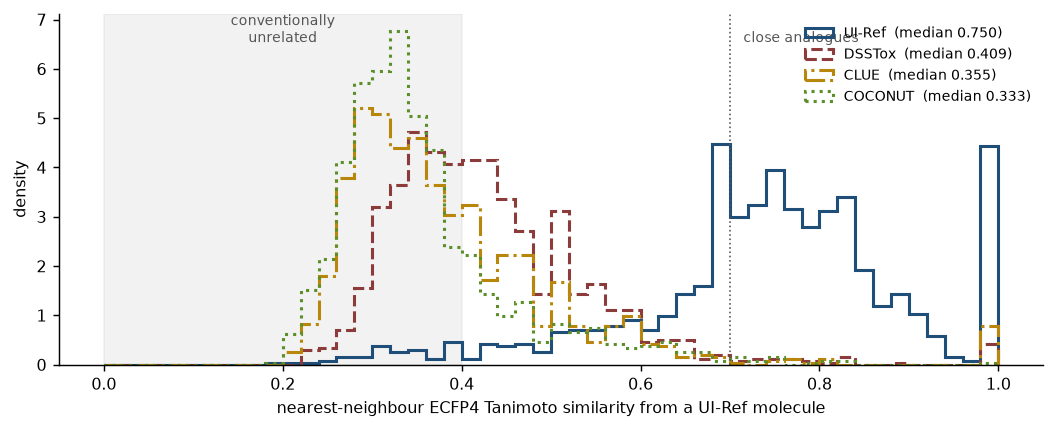

In [18]:
fig, ax = plt.subplots(figsize=(8.2, 3.4))
bins = np.linspace(0, 1, 51)
styles = [("UI-Ref", "#1f4e79", "-"), ("DSSTox", "#8c3b3b", "--"),
          ("CLUE", "#b8860b", "-."), ("COCONUT", "#5a8f29", ":")]
for name, colour, ls in styles:
    ax.hist(nn[name], bins=bins, histtype="step", linewidth=1.7, color=colour, linestyle=ls,
            density=True, label="%s  (median %.3f)" % (name, np.median(nn[name])))
ax.axvspan(0.0, 0.4, color="#cccccc", alpha=0.25)
ax.text(0.2, ax.get_ylim()[1] * 0.92, "conventionally\nunrelated", ha="center", fontsize=7.5, color="#555")
ax.axvline(0.7, color="#555", linewidth=0.9, linestyle=":")
ax.text(0.715, ax.get_ylim()[1] * 0.92, "close analogues", fontsize=7.5, color="#555")
ax.set_xlabel("nearest-neighbour ECFP4 Tanimoto similarity from a UI-Ref molecule")
ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=7.6)
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Distribution of the nearest-neighbour ECFP4 Tanimoto similarity
from each of the 1,218 UI-Ref molecules to the collection indicated, reproducing the paper's
Figure 4c. The within-UI-Ref curve (leave-one-out) is shifted far to the right of the three external
curves and has a mode above 0.9, reflecting near-duplicate analogues inside published series. All
three external distributions sit largely inside the grey band conventionally read as unrelated, with
medians of 0.409 (DSSTox), 0.355 (CLUE) and 0.333 (COCONUT).</p>

### 4.5 What a Tanimoto of 0.35 looks like

A number read off a histogram is easy to over-interpret in either direction. The next cell picks the
UI-Ref molecule whose CLUE nearest neighbour is closest to the median value of 0.355 and draws the
pair, so that the band can be calibrated by eye.

UI-Ref molecule : UIREF-0698   CCOC(=O)C1C(C)=NC(=S)NC1c1ccccc1
CLUE neighbour  : PCA-4248   COC(=O)C1=C(C)N=C(C)C(C(=O)OCCSc2ccccc2)[C@@H]1C
Tanimoto        : 0.3548   (median of the UI-Ref -> CLUE distribution: 0.3548)
shared bits: 22 of 39 and 45 set


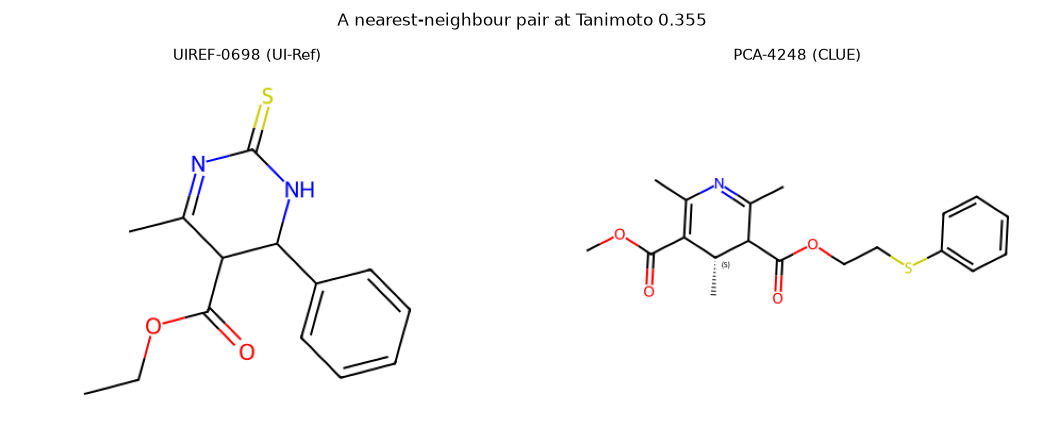

In [19]:
i_star = int(np.argmin(np.abs(nn["CLUE"] - np.median(nn["CLUE"]))))
j_star = int(np.argmax(DataStructs.BulkTanimotoSimilarity(fps["UI-Ref"][i_star], fps["CLUE"])))
ui_mol, clue_mol = uiref.iloc[i_star], clue.iloc[j_star]
t = DataStructs.TanimotoSimilarity(fps["UI-Ref"][i_star], fps["CLUE"][j_star])

print("UI-Ref molecule : %s   %s" % (ui_mol.row_id, ui_mol.smiles_std))
print("CLUE neighbour  : %s   %s" % (clue_mol.Name, clue_mol.smiles_std))
print("Tanimoto        : %.4f   (median of the UI-Ref -> CLUE distribution: %.4f)" %
        (t, np.median(nn["CLUE"])))
print("shared bits: %d of %d and %d set" %
        (len(set(fps["UI-Ref"][i_star].GetOnBits()) & set(fps["CLUE"][j_star].GetOnBits())),
         fps["UI-Ref"][i_star].GetNumOnBits(), fps["CLUE"][j_star].GetNumOnBits()))

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.2))
for ax, (m, lab) in zip(axes, [(Chem.MolFromSmiles(ui_mol.smiles_std), "%s (UI-Ref)" % ui_mol.row_id),
                               (Chem.MolFromSmiles(clue_mol.smiles_std), "%s (CLUE)" % clue_mol.Name)]):
    ax.imshow(draw_mol(m, size=(440, 320))); ax.set_title(lab, fontsize=8.5); ax.axis("off")
fig.suptitle("A nearest-neighbour pair at Tanimoto %.3f" % t, fontsize=9.5, y=1.0)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> A UI-Ref molecule and its nearest CLUE neighbour at Tanimoto
0.355, the median of that distribution. Left, UIREF-0698, an ethyl dihydropyrimidine-thione
carboxylate; right, PCA-4248, a dihydropyridine diester. They share a six-membered partially
saturated ring bearing an ester and a methyl group, and differ in the ring heteroatoms, the thione,
the second ester and the thioether side chain. This is what "the collections occupy the same chemical
space" means at the median: a common ring motif and otherwise different molecules.</p>

The pair cuts both ways: these compounds are not unrelated, but no one would use one to predict the
activity of the other. That is the operational meaning of the paper's statement that a median
similarity of 0.355 "does not support the interpretation that the collections contain close
structural analogues"<sup class="c"><a href="#r1">[1]</a></sup>.

## 5. Bemis-Murcko scaffolds

A **scaffold** in the sense of Bemis and Murcko is the molecular framework that remains after all
side chains are removed: keep every ring, keep every linker atom that lies on a path between two
rings, discard everything else<sup class="c"><a href="#r6">[6]</a></sup>. The definition is purely
graph-theoretic and therefore deterministic, which is what makes it useful as a grouping key. It is
not the only way to group structurally related molecules — fingerprint clustering at a fixed Tanimoto
threshold is the other standard choice, and the paper uses Butina clustering at 0.4 for its
chemical-space analysis<sup class="c"><a href="#r20">[20]</a></sup> — but a scaffold is reproducible
without choosing a threshold, which is why it is the unit used for validation splits.

In [20]:
from rdkit.Chem.Scaffolds import MurckoScaffold

examples = ["CC(=O)Oc1ccccc1C(=O)O",                       # aspirin
            "NC(=S)Nc1ccccc1",                             # phenylthiourea
            uiref.loc[uiref.row_id == "UIREF-1160", "smiles_std"].iloc[0],
            "CC(C)Cc1ccc(C(C)C(=O)O)cc1"]                  # ibuprofen
rows = []
for s in examples:
    m = Chem.MolFromSmiles(s)
    scaf = MurckoScaffold.GetScaffoldForMol(m)
    rows.append((s, Chem.MolToSmiles(scaf), scaf.GetNumHeavyAtoms(), m.GetNumHeavyAtoms()))
print(pd.DataFrame(rows, columns=["molecule", "Bemis-Murcko scaffold",
                                  "scaffold heavy atoms", "molecule heavy atoms"]).to_string(index=False))

# does the published scaffold column reproduce?
chk = uiref.sample(300, random_state=RANDOM_STATE)
with_stereo, without_stereo = [], []
for s in chk.smiles_std:
    scaf = MurckoScaffold.GetScaffoldForMol(Chem.MolFromSmiles(s))
    with_stereo.append(Chem.MolToSmiles(scaf))
    flat = Chem.Mol(scaf); Chem.RemoveStereochemistry(flat)
    without_stereo.append(Chem.MolToSmiles(flat))
print("\npublished column reproduced, stereochemistry kept   : %d of %d" %
        (sum(a == b for a, b in zip(with_stereo, chk.scaffold)), len(chk)))
print("published column reproduced, stereochemistry removed: %d of %d" %
        (sum(a == b for a, b in zip(without_stereo, chk.scaffold)), len(chk)))
print("example disagreement:")
for a, b in zip(with_stereo, chk.scaffold):
    if a != b:
        print("   with stereo : %s\n   as published: %s" % (a, b))
        break

                       molecule   Bemis-Murcko scaffold  scaffold heavy atoms  molecule heavy atoms
          CC(=O)Oc1ccccc1C(=O)O                c1ccccc1                     6                    13
                NC(=S)Nc1ccccc1                c1ccccc1                     6                    10
CN(C)c1ccc(/C=N/Nc2nc(O)cs2)cc1 C(=N\Nc1nccs1)/c1ccccc1                    14                    18
     CC(C)Cc1ccc(C(C)C(=O)O)cc1                c1ccccc1                     6                    15

published column reproduced, stereochemistry kept   : 283 of 300
published column reproduced, stereochemistry removed: 300 of 300
example disagreement:
   with stereo : O=C(CN1CCN(c2ccc3c(=O)ccn(C4CC4)c3c2)CC1)Nc1ccc(C(=O)/C=C/c2ccccc2)cc1
   as published: O=C(CN1CCN(c2ccc3c(=O)ccn(C4CC4)c3c2)CC1)Nc1ccc(C(=O)C=Cc2ccccc2)cc1


Aspirin's scaffold is bare benzene — the acetyl and the carboxylic acid are both side chains, so the
framework of an aspirin molecule and of a benzene molecule are identical. Phenylthiourea and ibuprofen
likewise reduce to benzene. That is the first thing to understand about scaffolds: the definition is
coarse, and it deliberately throws away the functional groups that often carry the activity.
UIREF-1160, with two rings joined by a hydrazone linker, keeps the linker and so retains a framework of
14 heavy atoms out of 18.

The reproduction check is instructive in itself. Computing scaffolds straightforwardly reproduces the
published column on 283 of 300 sampled molecules; removing stereochemistry from the scaffold first
reproduces it on all 300. The published column is therefore a *flattened* framework, and the 17
disagreements are all molecules whose scaffold carries a double-bond geometry — `C(=N\Nc1nccs1)/c1ccccc1`
against the published `C(=NNc1nccs1)c1ccccc1`. That is a reasonable convention for a grouping key, since
two geometric isomers should land in the same fold, but it is a convention and it is not written in the
column name.

Section 2.6 of the paper reports 214 scaffold classes over the 1,218 molecules, with 13 classes
covering half the dataset and 52 covering 80%<sup class="c"><a href="#r1">[1]</a></sup>. The question
behind that statistic is whether UI-Ref samples chemical space or samples a few series. **For the
paper's claim to be wrong, scaffold coverage would have to be flat** — hundreds of classes each
contributing a handful of molecules.

In [21]:
scaf = uiref.scaffold.replace("", "(acyclic)")
counts = scaf.value_counts()
cum = counts.cumsum() / len(uiref)
print("distinct Bemis-Murcko scaffold classes: %d" % counts.size)
print("acyclic class (no rings at all): %d molecules" % int((scaf == "(acyclic)").sum()))
print("classes covering 50%% of UI-Ref: %d" % int((cum < 0.5).sum() + 1))
print("classes covering 80%% of UI-Ref: %d" % int((cum < 0.8).sum() + 1))
print("singleton classes (one molecule only): %d" % int((counts == 1).sum()))

docs_per_scaffold = (uiref.dropna(subset=["primary_document"])
                          .groupby("scaffold").primary_document.nunique())
print("\nscaffold classes occurring in exactly one source document: %d of %d documented classes" %
        (int((docs_per_scaffold == 1).sum()), len(docs_per_scaffold)))
print("\nthe six largest classes:")
print(counts.head(6).rename("molecules").to_frame())

distinct Bemis-Murcko scaffold classes: 214
acyclic class (no rings at all): 55 molecules
classes covering 50% of UI-Ref: 13
classes covering 80% of UI-Ref: 52
singleton classes (one molecule only): 115

scaffold classes occurring in exactly one source document: 179 of 201 documented classes

the six largest classes:
                                 molecules
scaffold                                  
c1ccccc1                               275
O=C(NC(=S)Nc1ccccc1)c1ccccc1            68
(acyclic)                               55
S=C(NN=Cc1cc2ccccc2o1)Nc1ccccc1         36
O=c1c2ccccc2[se]n1-c1ccccc1             26
S=C(Nc1ccccc1)Nc1ccccc1                 24


There are 214 classes, 13 of which cover half the set and 52 of which cover 80% — the published
figures exactly. Fifty-five molecules have no ring at all and form the single acyclic class the paper
describes. Of the 201 classes represented among documented molecules, 179 occur in exactly one source
document, again matching<sup class="c"><a href="#r1">[1]</a></sup>.

The largest class is bare benzene with 275 molecules, which is a reminder of how coarse the
definition is: those 275 compounds are mono-aromatic molecules whose chemistry lives entirely in
their side chains. The second largest, with 68 molecules, is `O=C(NC(=S)Nc1ccccc1)c1ccccc1` — a
benzoyl thiourea, a genuine chemotype — and it is reported in only four documents.

<div class="box key">
<h4>Key idea — why a scaffold is a split unit</h4>
<p>If two molecules share a Bemis-Murcko framework they differ only in side chains, so a model that
has seen one has effectively seen a template for the other. Putting them on opposite sides of a
train/test split measures interpolation within a series, not generalisation to new chemistry.
Grouping folds by scaffold forces every member of a framework into the same fold. The paper uses
scaffold grouping for the tasks where no publication identifier exists — the external collections
carry none — and document grouping where one does<sup class="c"><a href="#r1">[1]</a></sup>. Notebook 3
measures what each kind of grouping is worth.</p>
</div>

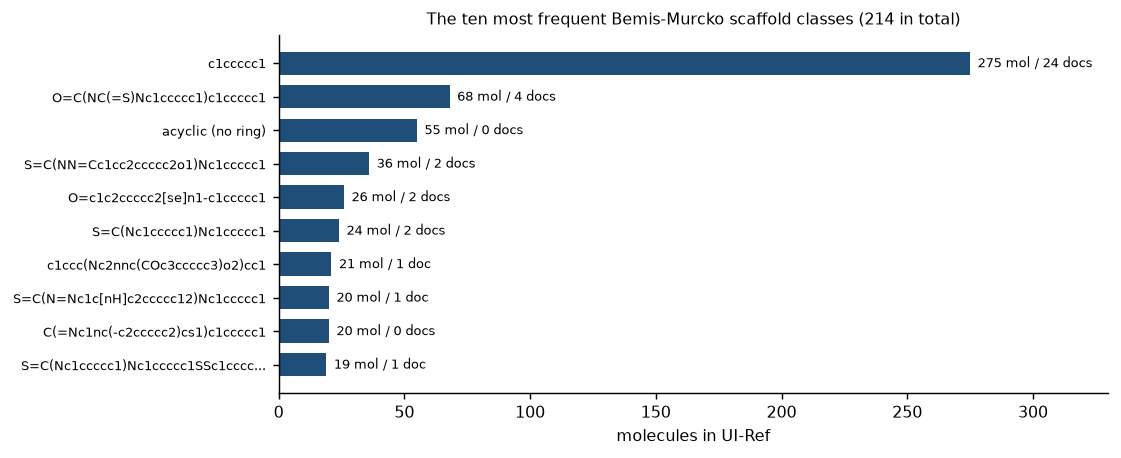

In [22]:
fig, ax = plt.subplots(figsize=(8.8, 3.6))
top = counts.head(10)[::-1]
labels = [("acyclic (no ring)" if s == "(acyclic)" else (s if len(s) <= 34 else s[:31] + "...")) for s in top.index]
ax.barh(np.arange(len(top)), top.values, color="#1f4e79", height=0.7)
ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(labels, fontsize=7)
for i, (v, s) in enumerate(zip(top.values, top.index)):
    nd = 0 if s == "(acyclic)" else int(docs_per_scaffold.get(s, 0))
    ax.text(v + 3, i, "%d mol / %d doc%s" % (v, nd, "" if nd == 1 else "s"), va="center", fontsize=7)
ax.set_xlabel("molecules in UI-Ref"); ax.set_xlim(0, 330)
ax.set_title("The ten most frequent Bemis-Murcko scaffold classes (214 in total)", fontsize=9)
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> The ten most frequent Bemis-Murcko scaffold classes in UI-Ref,
annotated with the number of distinct source documents each occurs in. Benzene dominates because the
definition strips side chains; the specific chemotypes below it — benzoyl thiourea, naphthofuran
thiosemicarbazone, phenyl benzisoselenazolone — each come from one to four publications, which is the
scaffold-level view of the document concentration measured in Notebook 0.</p>

## 6. SMARTS and structural motifs

### 6.1 Writing a pattern

SMARTS is SMILES extended into a query language: where SMILES names a specific molecule, SMARTS
describes a *pattern* that a molecule may or may not match. The additions are atom and bond
primitives in square brackets, combined with logical operators.

- `[#6]` any carbon, by atomic number, aromatic or not; `C` aliphatic carbon; `c` aromatic carbon.
- `[CX3]` a carbon with exactly three connections; `X` is total connectivity including hydrogens.
- `[OX1]` an oxygen with one connection — a carbonyl or similar; `[OX2H1]` an oxygen with two
  connections one of which is a hydrogen, that is, a hydroxyl.
- `[N,O]` nitrogen **or** oxygen (comma is logical or); `[C;R]` a carbon **and** in a ring
  (semicolon is low-precedence and); `[!c]` **not** aromatic carbon.
- `~` any bond, `-` single, `=` double, `:` aromatic.
- `$(...)` a recursive SMARTS: an atom that is itself the first atom of a matching pattern.

The paper assigns nine nickel-chelating and related motifs by SMARTS, and the discipline it applies
to them — validation against a fixed set of positive and negative controls, revalidated on every
run<sup class="c"><a href="#r1">[1]</a></sup> — is the most transferable habit in this notebook. We
build the patterns from scratch here.

In [23]:
SMARTS = {
    "hydroxamate":           "[CX3](=[OX1])[NX3][OX2H1,OX1-]",   # C(=O)-N-OH, the acetohydroxamic motif
    "thiourea":              "[NX3][CX3](=[SX1])[NX3]",          # N-C(=S)-N
    "urea":                  "[NX3][CX3](=[OX1])[NX3]",          # N-C(=O)-N
    "catechol":              "c(O)c(O)",                         # two oxygens on adjacent aromatic carbons
    "carboxylate":           "[CX3](=O)[OX2H1,OX1-]",            # COOH or COO-
    "thiol":                 "[#6][SX2H1]",                      # C-SH
    "hydrazone":             "[CX3]=[NX2][NX3]",                 # C=N-N
    "phosphinic_phosphonic": "[PX4](=O)([OX2H1,OX1-])",          # P(=O)(OH)
    "selenium":              "[Se]",                             # any selenium atom
}
queries = {k: Chem.MolFromSmarts(v) for k, v in SMARTS.items()}
print("all nine patterns compile:", all(q is not None for q in queries.values()))

for name in ["thiourea", "catechol", "hydroxamate"]:
    q = queries[name]
    print("\n%-12s %-34s -> %d query atoms, %d query bonds" %
            (name, SMARTS[name], q.GetNumAtoms(), q.GetNumBonds()))
    hits = Chem.MolFromSmiles("NC(=S)Nc1ccccc1").GetSubstructMatches(q)
    print("   matches in phenylthiourea: %s" % (hits,))

all nine patterns compile: True

thiourea     [NX3][CX3](=[SX1])[NX3]            -> 4 query atoms, 3 query bonds
   matches in phenylthiourea: ((0, 1, 2, 3),)

catechol     c(O)c(O)                           -> 4 query atoms, 3 query bonds
   matches in phenylthiourea: ()

hydroxamate  [CX3](=[OX1])[NX3][OX2H1,OX1-]     -> 4 query atoms, 3 query bonds
   matches in phenylthiourea: ()


The thiourea pattern matches phenylthiourea once, at atoms (0,1,2,3): the pattern is symmetric and
could be mapped from either nitrogen, but `GetSubstructMatches` uniquifies by atom set by default and
reports the match once. Pass `uniquify=False` and you get both mappings. For presence/absence work use
`HasSubstructMatch`, which short-circuits on the first hit; whenever you need to *count* occurrences,
read the documentation first, because symmetry makes counting a choice rather than a fact.

### 6.2 Positive and negative controls

A SMARTS pattern is code, and untested code is wrong. The paper validates its nine patterns against
eleven controls — acetohydroxamic acid, thiourea, urea, ebselen, catechol, benzoic acid, cysteine,
phenylhydrazone, phosphonoformic acid, aspirin and caffeine — and reports that all eleven behave as
specified<sup class="c"><a href="#r1">[1]</a></sup>. Nine of those are positive controls for one
motif each; aspirin and caffeine are the negative controls, chosen because they are near misses.
Caffeine in particular contains two `N–C(=O)–N` fragments and would match a naively written urea
pattern, but its nitrogens are aromatic, so the aliphatic `[NX3]` of our pattern correctly rejects it.

In [24]:
CONTROLS = {
    "acetohydroxamic acid":  ("CC(=O)NO",                    {"hydroxamate"}),
    "thiourea":              ("NC(=S)N",                     {"thiourea"}),
    "urea":                  ("NC(=O)N",                     {"urea"}),
    "ebselen":               ("O=C1c2ccccc2[Se]N1c1ccccc1",  {"selenium"}),
    "catechol":              ("Oc1ccccc1O",                  {"catechol"}),
    "benzoic acid":          ("OC(=O)c1ccccc1",              {"carboxylate"}),
    "cysteine":              ("SCC(N)C(=O)O",                {"carboxylate", "thiol"}),
    "phenylhydrazone":       ("c1ccccc1C=NN",                {"hydrazone"}),
    "phosphonoformic acid":  ("OC(=O)P(=O)(O)O",             {"carboxylate", "phosphinic_phosphonic"}),
    "aspirin  (negative)":   ("CC(=O)Oc1ccccc1C(=O)O",       {"carboxylate"}),
    "caffeine (negative)":   ("Cn1cnc2c1c(=O)n(C)c(=O)n2C",  set()),
}
rows, ok = [], 0
for name, (smi, expected) in CONTROLS.items():
    m = Chem.MolFromSmiles(smi)
    got = {k for k, q in queries.items() if m.HasSubstructMatch(q)}
    passed = got == expected
    ok += passed
    rows.append((name, ", ".join(sorted(expected)) or "(none)", ", ".join(sorted(got)) or "(none)",
                 "PASS" if passed else "FAIL"))
print("controls passing: %d of %d" % (ok, len(CONTROLS)))
pd.DataFrame(rows, columns=["control", "expected", "observed", "result"])

controls passing: 11 of 11


,control,expected,observed,result
0,acetohydroxamic acid,hydroxamate,hydroxamate,PASS
1,thiourea,thiourea,thiourea,PASS
2,urea,urea,urea,PASS
3,ebselen,selenium,selenium,PASS
4,catechol,catechol,catechol,PASS
5,benzoic acid,carboxylate,carboxylate,PASS
6,cysteine,"carboxylate, thiol","carboxylate, thiol",PASS
7,phenylhydrazone,hydrazone,hydrazone,PASS
8,phosphonoformic acid,"carboxylate, phosphinic_phosphonic","carboxylate, phosphinic_phosphonic",PASS
9,aspirin (negative),carboxylate,carboxylate,PASS


Eleven of eleven controls pass, matching the published validation. Notice what the negative controls
are doing. Aspirin is expected to match `carboxylate` and nothing else — it is a negative control for
`hydroxamate` and for `urea`, both of which a sloppier pattern would hit. Caffeine is expected to
match nothing at all despite containing two amide-like `N–C(=O)–N` fragments.

<div class="box key">
<h4>Key idea — a pattern is validated by what it rejects</h4>
<p>Checking that a SMARTS matches the thing it is named after is almost free and almost worthless; any
pattern that mentions the right atoms will pass. The information is in the negative controls: molecules
that contain the right atoms in the wrong arrangement, or the right arrangement in the wrong
hybridisation state. Choose them deliberately, keep them in the source file next to the pattern, and
re-run them on every execution, which is exactly what the paper's released package
does<sup class="c"><a href="#r1">[1]</a></sup>.</p>
</div>

The controls do not, however, tell you whether the pattern is right for *your dataset*. The next cell
applies all nine patterns to all 1,218 UI-Ref molecules and compares them against the motif columns of
the published table — an independent check on 1,218 real molecules rather than 11 textbook ones.

In [25]:
mols = [Chem.MolFromSmiles(s) for s in uiref.smiles_std]
rows = []
for name, q in queries.items():
    mine = np.array([m.HasSubstructMatch(q) for m in mols])
    published_col = uiref[name].to_numpy().astype(bool)
    rows.append((name, int(mine.sum()), int(published_col.sum()),
                 int((mine != published_col).sum())))
agreement = pd.DataFrame(rows, columns=["motif", "this notebook", "published column", "disagreements"])
agreement["prevalence %"] = (100 * agreement["published column"] / len(uiref)).round(2)
print(agreement.to_string(index=False))
print("\ntotal molecule-level disagreements across all nine motifs: %d of %d" %
        (agreement.disagreements.sum(), 9 * len(uiref)))

                motif  this notebook  published column  disagreements  prevalence %
          hydroxamate             21                21              0          1.72
             thiourea            303               303              0         24.88
                 urea             17                17              0          1.40
             catechol            172               172              0         14.12
          carboxylate             73                73              0          5.99
                thiol              2                 2              0          0.16
            hydrazone            118               118              0          9.69
phosphinic_phosphonic            100               100              0          8.21
             selenium             54                54              0          4.43

total molecule-level disagreements across all nine motifs: 0 of 10962


Nine patterns written from the motif names alone reproduce the published columns exactly: zero
disagreements over 10,962 molecule-by-motif decisions. That is a stronger reproducibility result than
it may look, because nothing constrained the pattern text — `catechol` could have been written in
several ways. It was not free, though, and the next cell shows the attempt that failed.

In [26]:
variants = {"c(O)c(O)                  (used above)": "c(O)c(O)",
            "c1cc(O)c(O)cc1            (benzene only)": "c1cc(O)c(O)cc1",
            "c([OX2H1])c([OX2H1])      (hydroxyl only)": "c([OX2H1])c([OX2H1])"}
published_col = uiref["catechol"].to_numpy().astype(bool)
for label, sma in variants.items():
    q = Chem.MolFromSmarts(sma)
    mine = np.array([m.HasSubstructMatch(q) for m in mols])
    print("%-42s matches %3d, disagreements %2d" % (label, mine.sum(), (mine != published_col).sum()))

q_ring = Chem.MolFromSmarts("c1cc(O)c(O)cc1")
missed = uiref[published_col & ~np.array([m.HasSubstructMatch(q_ring) for m in mols])]
print("\nthe molecule the benzene-specific pattern misses:")
print(missed[["row_id", "smiles_std"]].to_string(index=False))

c(O)c(O)                  (used above)     matches 172, disagreements  0
c1cc(O)c(O)cc1            (benzene only)   matches 171, disagreements  1
c([OX2H1])c([OX2H1])      (hydroxyl only)  matches 100, disagreements 72

the molecule the benzene-specific pattern misses:
    row_id               smiles_std
UIREF-0554 OC[C@H](O)c1oc(O)c(O)c1O


Three defensible readings of "catechol" give 172, 171 and 100 matches. The benzene-specific pattern
`c1cc(O)c(O)cc1` misses UIREF-0554, whose *ortho*-dihydroxy pair sits on a five-membered furan ring —
correct chemistry, wrong ring size in the query. The hydroxyl-only pattern `c([OX2H1])c([OX2H1])`
drops 72 molecules, because plain `O` in SMARTS matches any aliphatic oxygen: the published pattern
deliberately includes catechol *ethers* and methylenedioxy groups as well as free diols. Whether that
is the right definition is a chemical judgement, which is the point — the SMARTS encodes a judgement,
so the judgement must be written down beside it. None of the eleven controls would have caught either
difference.

<div class="box warn">
<h4>Pitfall — the pattern that is nearly right</h4>
<p>A SMARTS that is 99% right looks exactly like one that is 100% right: no error, no warning, a
plausible count. The only defences are negative controls chosen to probe the specific ways the pattern
could over- or under-match, and a cross-check against an independent count whenever one exists. The
paper itself reports a residual discrepancy of this kind — its frozen patterns differ from an earlier
count by between −11 and +1 molecules across the nine motifs, and it publishes the
difference<sup class="c"><a href="#r1">[1]</a></sup>.</p>
</div>

### 6.3 Prevalence in UI-Ref and in the drug library

With validated patterns we can ask a chemically meaningful question: how much more common is a urease
chemotype in the urease set than in a drug library? The paper reports that thiourea occurs in 24.88%
of UI-Ref but only 0.27% of CLUE, a 91.9-fold
difference<sup class="c"><a href="#r1">[1]</a></sup>.

In [27]:
clue_mols = [Chem.MolFromSmiles(s) for s in clue.smiles_std]
prev = []
for name, q in queries.items():
    p_ui = 100 * np.mean([m.HasSubstructMatch(q) for m in mols])
    p_cl = 100 * np.mean([m.HasSubstructMatch(q) for m in clue_mols])
    prev.append((name, p_ui, p_cl, (p_ui / p_cl) if p_cl > 0 else np.inf))
prevalence = pd.DataFrame(prev, columns=["motif", "UI-Ref %", "CLUE %", "fold difference"])
prevalence = prevalence.sort_values("UI-Ref %", ascending=False).round(3)
print(prevalence.to_string(index=False))
print("\nmolecules with at least one chelating motif: UI-Ref %.1f%% (published column: %.1f%%)" %
        (100 * np.mean([any(m.HasSubstructMatch(q) for q in queries.values()) for m in mols]),
         100 * uiref.any_chelator.mean()))

                motif  UI-Ref %  CLUE %  fold difference
             thiourea    24.877   0.271           91.858
             catechol    14.122   6.861            2.058
            hydrazone     9.688   0.903           10.732
phosphinic_phosphonic     8.210   1.873            4.383
          carboxylate     5.993  18.619            0.322
             selenium     4.433   0.068           65.483
          hydroxamate     1.724   0.113           15.279
                 urea     1.396   3.656            0.382
                thiol     0.164   0.519            0.316

molecules with at least one chelating motif: UI-Ref 57.3% (published column: 57.3%)


Thiourea occurs in 24.88% of UI-Ref and 0.271% of CLUE — a 91.9-fold difference, reproducing the
published value exactly. Selenium follows at 65-fold and hydrazone at 11-fold. Two motifs run the other
way: carboxylate is three times more common in the drug library (18.6% against 6.0%) and urea nearly
three times (3.7% against 1.4%), which is what you would expect of a collection of approved drugs.
Catechol is enriched only 2.1-fold, because the pattern used here also matches catechol ethers, which
are common in natural-product-derived drugs. At least one chelating motif is present in 57.3% of
UI-Ref molecules, matching the `any_chelator` column.

This is the sharpest piece of chemistry in the case study, and it cuts both ways. The enrichment is
genuine — thiourea really is a urease chemotype, for the mechanistic reason given in Notebook 0 — and
it is also the clearest demonstration that property matching cannot fix the comparison. After matching
on molecular weight, cLogP, TPSA and heavy-atom count, the standardised mean difference for thiourea
is still 0.800, 0.796 and 0.753 against the three collections, essentially unchanged from before
matching<sup class="c"><a href="#r1">[1]</a></sup>. Balancing four physicochemical properties can
leave the substructure composition of the two classes completely different, which is why the paper
declines to call the matched comparison balanced. Notebook 3 reproduces that table.

### 6.4 Alert catalogues

Beyond hand-written motifs, RDKit ships curated **filter catalogues**: large published SMARTS sets
flagging substructures associated with assay interference or undesirable properties. The paper uses
three<sup class="c"><a href="#r1">[1]</a></sup>. PAINS — pan-assay interference compounds — are
substructures found recurring as apparent hits across unrelated AlphaScreen
assays<sup class="c"><a href="#r7">[7]</a></sup>; the Brenk set collects substructures judged
unsuitable for neglected-disease screening
libraries<sup class="c"><a href="#r8">[8]</a></sup>; the NIH set is a third, partly overlapping
compilation.

In [28]:
from rdkit.Chem import FilterCatalog
from rdkit.Chem.FilterCatalog import FilterCatalogParams

catalogues = {}
for label, which in [("PAINS", FilterCatalogParams.FilterCatalogs.PAINS),
                     ("BRENK", FilterCatalogParams.FilterCatalogs.BRENK),
                     ("NIH",   FilterCatalogParams.FilterCatalogs.NIH)]:
    p = FilterCatalogParams(); p.AddCatalog(which)
    catalogues[label] = FilterCatalog.FilterCatalog(p)
print("catalogue sizes: " + ", ".join("%s %d patterns" % (k, c.GetNumEntries())
                                      for k, c in catalogues.items()))

rows = []
for label, cat in catalogues.items():
    flag = np.array([cat.HasMatch(m) for m in mols])
    rows.append((label, 100 * flag.mean(), 100 * uiref[label].mean(), int((flag != uiref[label].to_numpy().astype(bool)).sum())))
alerts = pd.DataFrame(rows, columns=["catalogue", "this notebook %", "published column %", "disagreements"])
print(alerts.round(2).to_string(index=False))

entry = catalogues["PAINS"].GetFirstMatch(mols[int(np.argmax([catalogues["PAINS"].HasMatch(m) for m in mols]))])
print("\nexample PAINS flag raised in UI-Ref: %s" % entry.GetDescription())

catalogue sizes: PAINS 480 patterns, BRENK 105 patterns, NIH 180 patterns
catalogue  this notebook %  published column %  disagreements
    PAINS            19.21               19.21              0
    BRENK            84.81               84.81              0
      NIH            21.18               21.18              0

example PAINS flag raised in UI-Ref: catechol_A(92)


Brenk alerts occur in 84.81% of UI-Ref molecules, NIH alerts in 21.18% and PAINS in 19.21%,
reproducing the published columns with zero disagreements and matching the paper's reported 84.8%,
21.2% and 19.2%<sup class="c"><a href="#r1">[1]</a></sup>.

Those are remarkable numbers and they need careful reading. An 84.8% Brenk rate does not mean that
85% of reported urease inhibitors are bad compounds. It means that the Brenk catalogue flags
substructures — thioureas and hydrazones prominently among them — that happen to be the chemistry the
urease literature is built on. The alert catalogues were compiled against screening libraries of
general-purpose chemistry; applied to a target-focused set whose mechanism *requires* metal
chelation, they flag the mechanism. The paper makes the corresponding methodological point in its
cascade analysis: a model trained to predict alert status is solving a deterministic SMARTS
calculation, so it adds no information and is retained only as a
diagnostic<sup class="c"><a href="#r1">[1]</a></sup>.

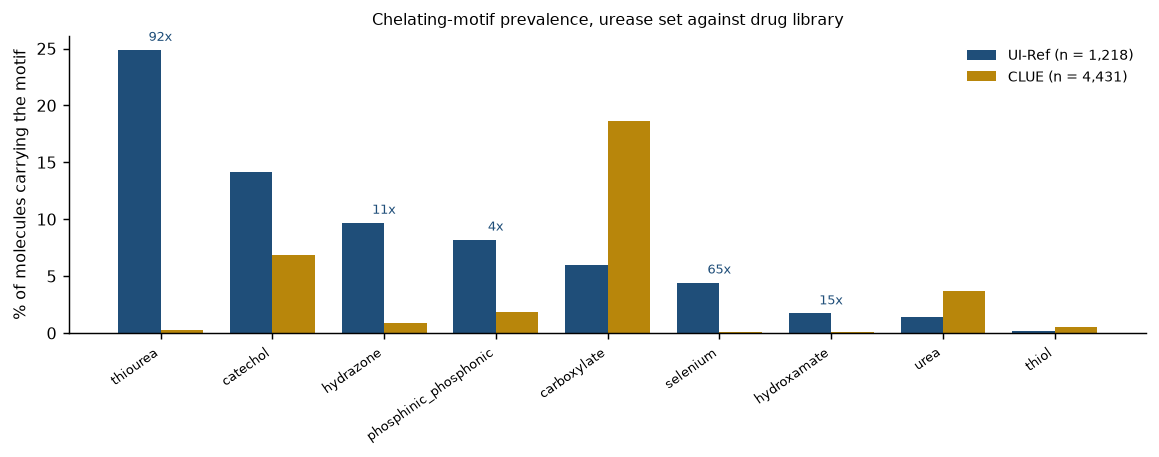

In [29]:
motifs_plot = prevalence.set_index("motif")
fig, ax = plt.subplots(figsize=(9.0, 3.6))
idx = np.arange(len(motifs_plot))
ax.bar(idx - 0.19, motifs_plot["UI-Ref %"], width=0.38, color="#1f4e79", label="UI-Ref (n = 1,218)")
ax.bar(idx + 0.19, motifs_plot["CLUE %"], width=0.38, color="#b8860b", label="CLUE (n = 4,431)")
for i, (u, c) in enumerate(zip(motifs_plot["UI-Ref %"], motifs_plot["CLUE %"])):
    if c > 0 and u / c > 3:
        ax.text(i, u + 0.8, "%.0fx" % (u / c), ha="center", fontsize=7.2, color="#1f4e79")
ax.set_xticks(idx); ax.set_xticklabels(motifs_plot.index, rotation=35, ha="right", fontsize=7.4)
ax.set_ylabel("% of molecules carrying the motif")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Chelating-motif prevalence, urease set against drug library", fontsize=9)
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> Prevalence of the nine chelating and related motifs in UI-Ref and
in CLUE, computed with the SMARTS patterns validated above, with fold differences annotated where they
exceed three. Thiourea is enriched 92-fold, selenium 65-fold, hydroxamate 15-fold and hydrazone
11-fold; carboxylate and urea are instead more common in the drug library. These differences survive
physicochemical property matching, which is why the paper reports the matched comparison as unbalanced
on substructure composition<sup class="c"><a href="#r1">[1]</a></sup>.</p>

<div class="exercise">
<h4>Exercise 3</h4>
<p>Add a tenth motif to the <code>SMARTS</code> dictionary — a sulfonamide, say, written as
<code>[SX4](=O)(=O)[NX3]</code> — together with one positive control (sulfanilamide,
<code>Nc1ccc(S(N)(=O)=O)cc1</code>) and one negative control that contains a sulfone but no
sulfonamide (<code>CS(C)(=O)=O</code>). Re-run the control cell and the prevalence cell, and report
the fold difference between UI-Ref and CLUE.</p>
</div>

## 7. What a descriptor vector does not capture

Everything in this notebook maps a molecular graph to numbers. It is worth stating plainly what is
lost in that map, because the limitations explain several of the paper's results.

<div class="box warn">
<h4>What the representations used here do not encode</h4>
<ul>
<li><strong>Three-dimensional structure.</strong> Every descriptor and fingerprint computed here is a
function of the graph. Two diastereomers with identical connectivity have identical ECFP4
fingerprints unless chirality is explicitly turned on, and no conformational information is present
at all. The coordinates in Figures 1, 2, 6 and 7 were generated for drawing and are not geometry.</li>
<li><strong>Protonation and tautomeric state at pH.</strong> A standardised structure is one
representative; the species present in an assay buffer at pH 7.4 may be a different tautomer, a
different protonation state, or a mixture. Section 2.2 showed that the choice of representative can
decide whether a compound is a known inhibitor or an unknown.</li>
<li><strong>The target.</strong> Nothing in a descriptor vector knows that urease has two nickel ions.
A model trained on these features can only learn which molecules resemble which other molecules; the
mechanism is supplied by the analyst, not by the data.</li>
<li><strong>Assay context.</strong> Organism, enzyme preparation, buffer, incubation time and the
reference compound used for normalisation are all absent from the molecular representation while
being strongly associated with the source publication — the confounding structure of Notebook 0.</li>
<li><strong>Concentration and exposure.</strong> A descriptor vector cannot distinguish a compound
that inhibits at 10 nM from one that inhibits at 10 mM; that information is in the label, and
Notebook 0 showed how much curation it takes to get the label right.</li>
</ul>
</div>

None of this argues against descriptors and fingerprints. They are cheap, reproducible and sufficient
for a great deal of work, and the paper's central result — that 25 of them predict the depositing
database with AUC 0.954 — depends on their being *informative*, not complete. The argument is for
knowing the boundary: when a model built on these features separates two groups, the explanation must
lie in a graph-encodable difference between the groups, and how a collection was assembled is one such
difference.

## 8. Summary

You should be able to explain the following without notes.

- A SMILES string encodes a molecular graph given a set of valence and aromaticity conventions; many
  strings denote the same molecule, and canonicalisation picks one — but only within one toolkit and
  one version.
- Standardisation maps depositor structures onto one form through sanitisation, largest-fragment
  selection, normalisation and tautomer canonicalisation. The fourth step changes molecular identity:
  the paper's worked example turns a known measured inhibitor into an unseen compound by changing
  nothing but the tautomer convention.
- An InChIKey hashes the skeleton in its first 14 characters and stereochemistry, isotopes and charge
  in the next 8. Tautomers differ in the first block; stereoisomers differ only in the second. The
  hash cannot be inverted.
- The 25 descriptors fall into five families and reproduce exactly from `smiles_std`. Eighteen of the
  300 descriptor pairs correlate above 0.95 and the correlation matrix is numerically singular.
- A Morgan/ECFP4 fingerprint is the set of hashed circular-substructure identifiers at radii 0, 1 and
  2, folded into 2,048 bits. Folding causes collisions, so a single bit is not a functional group.
- Tanimoto similarity is $c/(a+b-c)$ over set bits. Thiourea and phenylthiourea score 0.25. Within
  UI-Ref the median nearest neighbour is at 0.750; to CLUE, DSSTox and COCONUT it is 0.355, 0.409 and
  0.333, which is the "unrelated for practical purposes" band.
- A Bemis-Murcko scaffold is the ring systems plus their linkers. UI-Ref has 214 classes, 13 covering
  half the set, and 179 of the 201 documented classes occur in exactly one publication — which is why
  scaffold is a defensible grouping unit for a split.
- A SMARTS pattern encodes a chemical judgement and must be validated with negative controls as well
  as positive ones. Three defensible readings of "catechol" give 172, 171 and 100 matches in the same
  1,218 molecules.
- Thiourea is present in 24.88% of UI-Ref against 0.271% of CLUE, a 92-fold difference that survives
  physicochemical property matching.

## 9. Self-assessment

<details><summary>Q1. Why can the same SMILES string give different molecules in two different
toolkits?</summary>
Because the string does not specify hydrogen counts or aromaticity; the parser fills them in from
conventions that differ between implementations. An InChI, defined by a published algorithm, does
not have this problem.</details>

<details><summary>Q2. Which standardisation step would you remove if you had to remove one, and
which would you never remove?</summary>
Tautomer canonicalisation: it changes molecular identity and its representative is a convention.
Never remove sanitisation — without it invalid chemistry propagates silently into missing
descriptors.</details>

<details><summary>Q3. Two records have InChIKeys that agree in the first 14 characters but differ
afterwards. What is the relationship between the two structures?</summary>
Same molecular formula, connectivity and hydrogen layer; different stereochemistry, isotopic
composition or charge. Typically a pair of stereoisomers.</details>

<details><summary>Q4. The descriptor matrix has 25 columns but is numerically singular. Name two
descriptors that are the same number in UI-Ref and explain why.</summary>
<code>NumAtoms</code> and <code>NumHeavyAtoms</code>: <code>GetNumAtoms()</code> counts explicit atoms
only, and no molecule in the standardised set carries explicit hydrogens. <code>MolWt</code> and
<code>ExactMolWt</code> are a second pair, correlating at 1.0000 because they differ only by isotope
averaging.</details>

<details><summary>Q5. What does the "4" in ECFP4 refer to, and what is the corresponding RDKit
argument?</summary>
Diameter 4, that is <code>radius=2</code> in <code>GetMorganGenerator</code>. The naming counts bonds
across the circular environment rather than out from its centre.</details>

<details><summary>Q6. You find that bit 1,234 is set in 80% of your actives and 5% of your inactives.
Can you report it as a structural alert?</summary>
Not without resolving it: use <code>AdditionalOutput().AllocateBitInfoMap()</code> to list the atom
environments mapping to that bit across your dataset. Only if they all resolve to one substructure can
you name it.</details>

<details><summary>Q7. Thiourea and phenylthiourea share the thiourea group, yet their Tanimoto is
0.25. Explain.</summary>
A fingerprint records atom environments, not groups. The phenyl ring adds many environments to the
union and alters one nitrogen's environment, so the shared fraction is small even with the named group
intact. Size differences dominate fingerprint similarity.</details>

<details><summary>Q8. The median nearest-neighbour Tanimoto from UI-Ref to CLUE is 0.355 and within
UI-Ref is 0.750. Which of these two numbers is a problem for machine learning, and why?</summary>
Both, for opposite reasons. 0.750 within the set means near-duplicate analogues, so a random
train/test split leaks; 0.355 to CLUE means external libraries are structurally remote, so a model
trained on UI-Ref is extrapolating when applied to them — the applicability-domain result of Notebook
5.</details>

<details><summary>Q9. Why is benzene the largest Bemis-Murcko scaffold class in UI-Ref?</summary>
Because the definition keeps rings and linkers and discards side chains, so every mono-aromatic
molecule whose functionality hangs off one benzene ring — aspirin, phenylthiourea, 275 UI-Ref
molecules — reduces to the same framework.</details>

<details><summary>Q10. Caffeine contains two N–C(=O)–N fragments but is a negative control for the
urea motif. Why does it pass?</summary>
Its ring nitrogens are aromatic. The pattern <code>[NX3][CX3](=[OX1])[NX3]</code> uses upper-case
<code>N</code>, which in SMARTS matches aliphatic nitrogen only, so the aromatic ring nitrogens do not
match.</details>

<details><summary>Q11. Three readings of "catechol" gave 172, 171 and 100 matches. How would you
decide which to publish?</summary>
State the chemical intent first — free ortho-diol only, or any ortho-dioxygen pattern including
ethers — write the pattern to match it, then add negative controls that distinguish the readings (a
catechol methyl ether, a furan-2,3-diol). Publish pattern, intent and controls together.</details>

<details><summary>Q12. Brenk alerts flag 84.81% of UI-Ref. Is this evidence that most reported urease
inhibitors are unsuitable compounds?</summary>
No. The catalogues were compiled against general screening libraries and flag exactly the chelating
chemistry a nickel metalloenzyme inhibitor needs. Applied to a mechanistically focused set, an alert
catalogue flags the mechanism.
</details>

## Glossary

<dl class="gloss">
<dt>SMILES</dt><dd>Simplified Molecular Input Line Entry System: a line notation for a molecular
graph. Many strings denote the same molecule.</dd>
<dt>Canonical SMILES</dt><dd>The one string a toolkit emits for a molecule after a deterministic atom
ordering. Canonical within that toolkit and version only.</dd>
<dt>Standardisation</dt><dd>Mapping depositor structures onto one representative form.</dd>
<dt>Tautomer</dt><dd>One of several structures interconvertible by formal proton shifts. Tautomers
differ in the first InChIKey block.</dd>
<dt>InChIKey</dt><dd>A 27-character hash of an InChI: 14 characters for the skeleton, 8 for
stereochemistry/isotopes, plus flag, version and protonation characters. One-way.</dd>
<dt>Descriptor</dt><dd>A function from a molecular graph to a number. The paper uses 25.</dd>
<dt>TPSA</dt><dd>Topological polar surface area: the summed surface contribution of N and O atoms and
their hydrogens, used as a permeability proxy.</dd>
<dt>FractionCSP3</dt><dd>Fraction of carbon atoms that are sp3-hybridised; the usual one-number
measure of three-dimensionality.</dd>
<dt>ECFP4 / Morgan fingerprint</dt><dd>Hashed circular-substructure identifiers at radii 0 to 2,
folded into a fixed-length bit vector. Diameter 4 equals radius 2.</dd>
<dt>Bit collision</dt><dd>Two different substructures mapping to the same fingerprint bit after
folding. Unavoidable at fixed length.</dd>
<dt>Tanimoto coefficient</dt><dd>|A ∩ B| / |A ∪ B| over set bits; the standard fingerprint similarity
measure. Not a percentage.</dd>
<dt>Bemis-Murcko scaffold</dt><dd>The molecular framework: all rings plus the linker atoms between
them, with side chains removed.</dd>
<dt>SMARTS</dt><dd>A substructure query language extending SMILES with atom and bond primitives and
logical operators.</dd>
<dt>Structural alert</dt><dd>A published SMARTS pattern associated with assay interference or
undesirable properties; PAINS, Brenk and NIH are three such catalogues.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Farías-Abarca J, Urra G, Henríquez C, Yáñez O, Osorio MI, Palma J, Morales-Quintana L,
Suardíaz R, Bustos D. Provenance-Associated Confounding in Cross-Collection Comparisons of Urease
Inhibitors: A Quantified Reference Scale and a Domain-Aware Alternative. <em>Int. J. Mol. Sci.</em>
2026;27(20):9159. <a href="https://doi.org/10.3390/ijms27209159">doi:10.3390/ijms27209159</a></li>
<li id="r2">Weininger D. SMILES, a chemical language and information system. 1. Introduction to
methodology and encoding rules. <em>J. Chem. Inf. Comput. Sci.</em> 1988;28(1):31–36.
<a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r3">Heller SR, McNaught A, Pletnev I, Stein S, Tchekhovskoi D. InChI, the IUPAC International
Chemical Identifier. <em>J. Cheminform.</em> 2015;7:23.
<a href="https://doi.org/10.1186/s13321-015-0068-4">doi:10.1186/s13321-015-0068-4</a></li>
<li id="r4">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J. Chem. Inf. Model.</em>
2010;50(5):742–754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r5">Morgan HL. The Generation of a Unique Machine Description for Chemical Structures — A
Technique Developed at Chemical Abstracts Service. <em>J. Chem. Doc.</em> 1965;5(2):107–113.
<a href="https://doi.org/10.1021/c160017a018">doi:10.1021/c160017a018</a></li>
<li id="r6">Bemis GW, Murcko MA. The Properties of Known Drugs. 1. Molecular Frameworks.
<em>J. Med. Chem.</em> 1996;39(15):2887–2893.
<a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r7">Baell JB, Holloway GA. New Substructure Filters for Removal of Pan Assay Interference
Compounds (PAINS) from Screening Libraries and for Their Exclusion in Bioassays.
<em>J. Med. Chem.</em> 2010;53(7):2719–2740.
<a href="https://doi.org/10.1021/jm901137j">doi:10.1021/jm901137j</a></li>
<li id="r8">Brenk R, Schipani A, James D, et al. Lessons learnt from assembling screening libraries for
drug discovery for neglected diseases. <em>ChemMedChem</em> 2008;3(3):435–444.
<a href="https://doi.org/10.1002/cmdc.200700139">doi:10.1002/cmdc.200700139</a></li>
<li id="r9">Landrum G. RDKit: Open-source cheminformatics. <a href="https://www.rdkit.org">www.rdkit.org</a>
(accessed 20 September 2026). The toolkit used for every molecular computation in this series; no DOI
is minted for the software itself.</li>
<li id="r10">Fourches D, Muratov E, Tropsha A. Trust, But Verify: On the Importance of Chemical
Structure Curation in Cheminformatics and QSAR Modeling Research. <em>J. Chem. Inf. Model.</em>
2010;50(7):1189–1204. <a href="https://doi.org/10.1021/ci100176x">doi:10.1021/ci100176x</a></li>
<li id="r11">Bento AP, Hersey A, Félix E, et al. An open source chemical structure curation pipeline
using RDKit. <em>J. Cheminform.</em> 2020;12:51.
<a href="https://doi.org/10.1186/s13321-020-00456-1">doi:10.1186/s13321-020-00456-1</a></li>
<li id="r12">Sitzmann M, Ihlenfeldt W-D, Nicklaus MC. Tautomerism in large databases.
<em>J. Comput. Aided Mol. Des.</em> 2010;24(6–7):521–551.
<a href="https://doi.org/10.1007/s10822-010-9346-4">doi:10.1007/s10822-010-9346-4</a></li>
<li id="r13">Bajusz D, Rácz A, Héberger K. Why is Tanimoto index an appropriate choice for
fingerprint-based similarity calculations? <em>J. Cheminform.</em> 2015;7:20.
<a href="https://doi.org/10.1186/s13321-015-0069-3">doi:10.1186/s13321-015-0069-3</a></li>
<li id="r14">Maggiora G, Vogt M, Stumpfe D, Bajorath J. Molecular similarity in medicinal chemistry.
<em>J. Med. Chem.</em> 2014;57(8):3186–3204.
<a href="https://doi.org/10.1021/jm401411z">doi:10.1021/jm401411z</a></li>
<li id="r15">Wildman SA, Crippen GM. Prediction of Physicochemical Parameters by Atomic
Contributions. <em>J. Chem. Inf. Comput. Sci.</em> 1999;39(5):868–873.
<a href="https://doi.org/10.1021/ci990307l">doi:10.1021/ci990307l</a></li>
<li id="r16">Ertl P, Rohde B, Selzer P. Fast calculation of molecular polar surface area as a sum of
fragment-based contributions and its application to the prediction of drug transport properties.
<em>J. Med. Chem.</em> 2000;43(20):3714–3717.
<a href="https://doi.org/10.1021/jm000942e">doi:10.1021/jm000942e</a></li>
<li id="r17">Bertz SH. The first general index of molecular complexity.
<em>J. Am. Chem. Soc.</em> 1981;103(12):3599–3601.
<a href="https://doi.org/10.1021/ja00402a071">doi:10.1021/ja00402a071</a></li>
<li id="r18">Lipinski CA, Lombardo F, Dominy BW, Feeney PJ. Experimental and computational approaches
to estimate solubility and permeability in drug discovery and development settings.
<em>Adv. Drug Deliv. Rev.</em> 2012;64(Suppl.):4–17.
<a href="https://doi.org/10.1016/j.addr.2012.09.019">doi:10.1016/j.addr.2012.09.019</a></li>
<li id="r19">Veber DF, Johnson SR, Cheng H-Y, Smith BR, Ward KW, Kopple KD. Molecular properties that
influence the oral bioavailability of drug candidates. <em>J. Med. Chem.</em> 2002;45(12):2615–2623.
<a href="https://doi.org/10.1021/jm020017n">doi:10.1021/jm020017n</a></li>
<li id="r20">Butina D. Unsupervised Data Base Clustering Based on Daylight's Fingerprint and Tanimoto
Similarity: A Fast and Automated Way To Cluster Small and Large Data Sets.
<em>J. Chem. Inf. Comput. Sci.</em> 1999;39(4):747–750.
<a href="https://doi.org/10.1021/ci9803381">doi:10.1021/ci9803381</a></li>
<li id="r21">Kafarski P, Talma M. Recent advances in design of new urease inhibitors: A review.
<em>J. Adv. Res.</em> 2018;13:101–112.
<a href="https://doi.org/10.1016/j.jare.2018.01.007">doi:10.1016/j.jare.2018.01.007</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>, revised ed. Springer, 2007.
Chapters 1–5 cover representation, descriptors, fingerprints and similarity in the order used
here.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>, 3rd ed.
O'Reilly, 2022. Chapter 2 for the feature-engineering habits this notebook assumes.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning
with Applications in Python</em>. Springer, 2023. Free PDF at
<a href="https://www.statlearning.com/">statlearning.com</a>; Chapter 6 on collinearity.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li><a href="https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html">Daylight SMARTS theory
manual</a> — the authoritative specification of the pattern language, including every atom and bond
primitive used in Section 6.</li>
<li><a href="https://www.rdkit.org/docs/GettingStartedInPython.html">RDKit: Getting Started in
Python</a> — worked examples for every function called in this notebook, and
<a href="https://greglandrum.github.io/rdkit-blog/">Greg Landrum's RDKit blog</a> for the behaviour
of fingerprints, tautomers and filter catalogues in detail.</li>
<li><a href="https://github.com/DanielBustosG/Urease-provenance-audit">Urease-provenance-audit</a> —
the released repository: the frozen SMARTS patterns, their control set, and the standardisation
pipeline reproduced in Section 2.</li>
</ul>